In [48]:
# Import packages
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import copy
import os
import datetime
import matplotlib as mpl
import pwlf

In [3]:
sites = ['GG1','WP1','WP2','DD']#'GN', GN excluded for now becauase data aren't on irrimax portal

# What do diel waves look like at Sentek sensors?
This section examines each sensor separately to identify a standard shape of a diel oscillation. The code removes a daily trend from drainage and examines the standard shape of the subdaily soil moisture. The shape is typically the same year-round and doesn't always show up. 

GG1


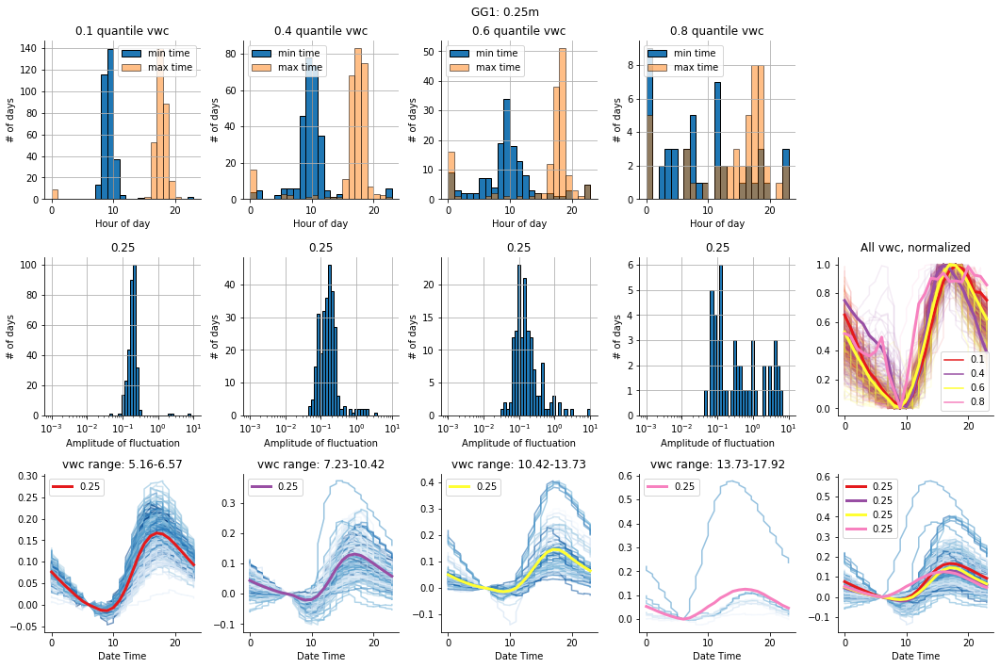

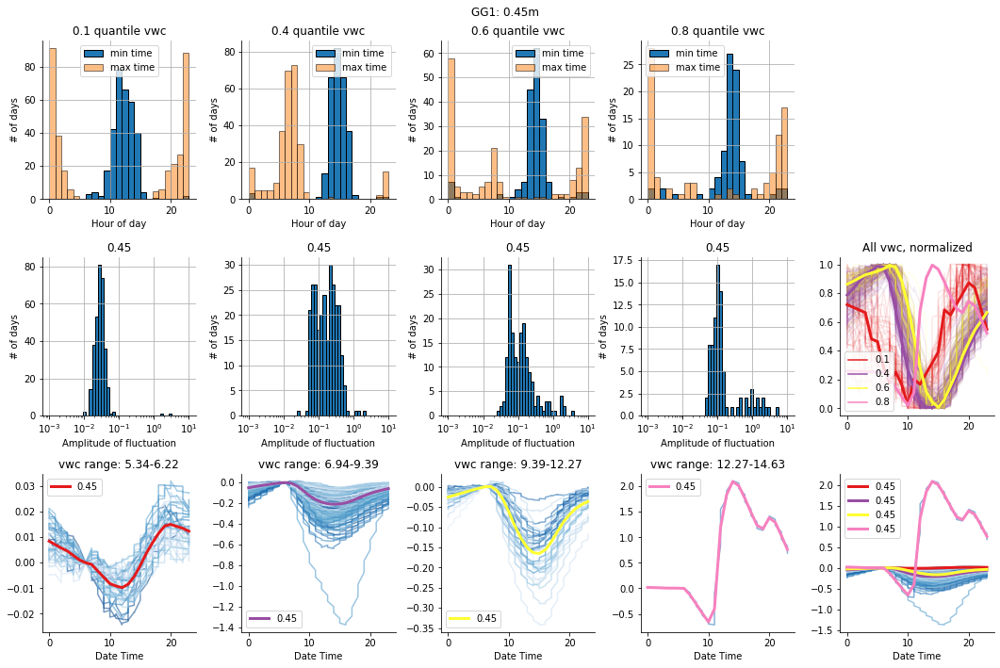

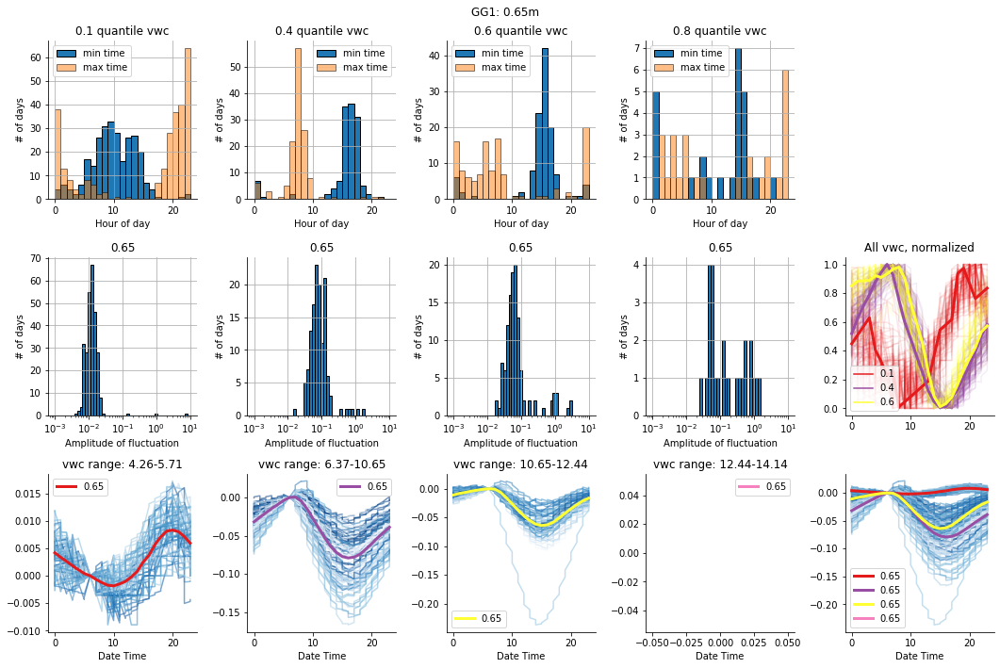

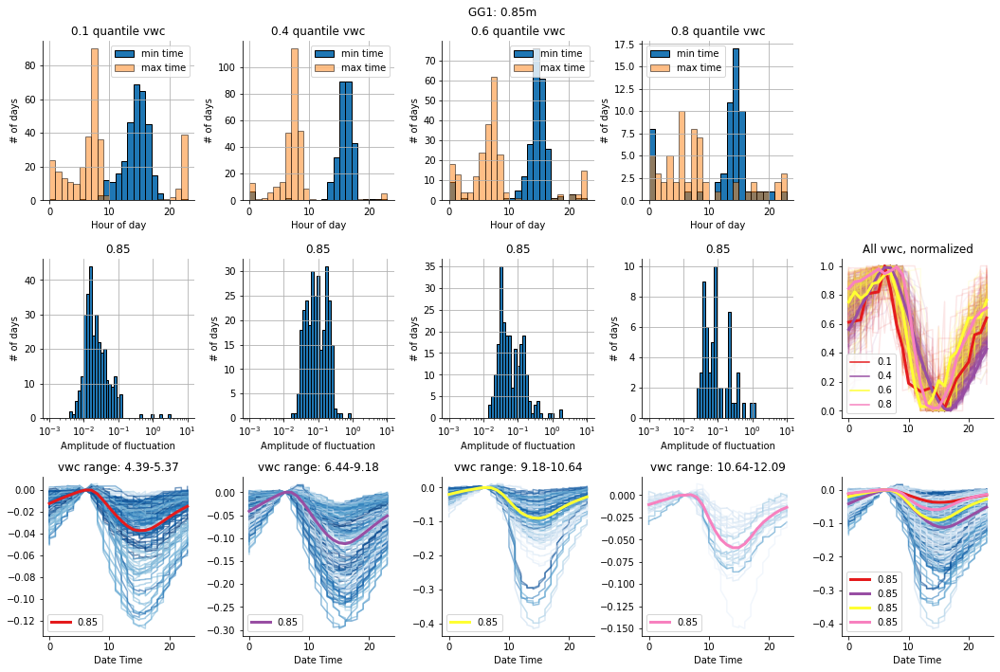

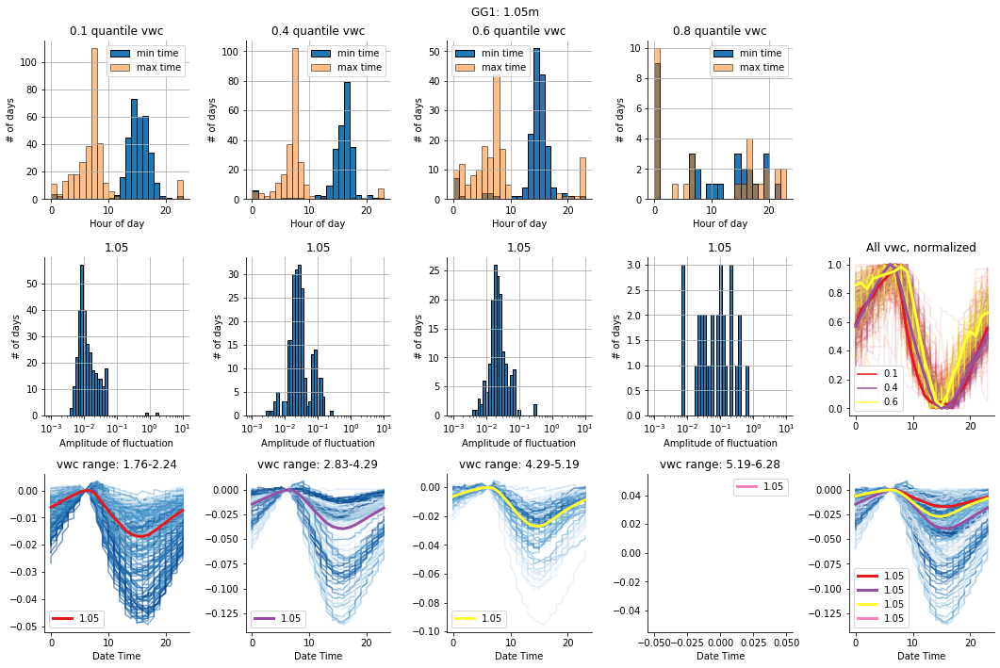

...

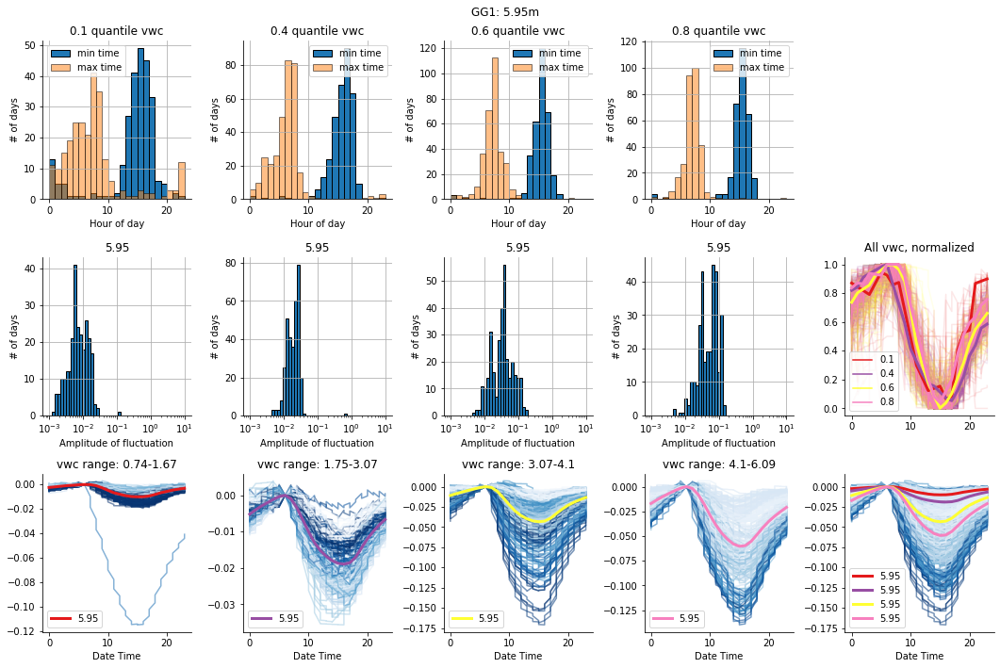

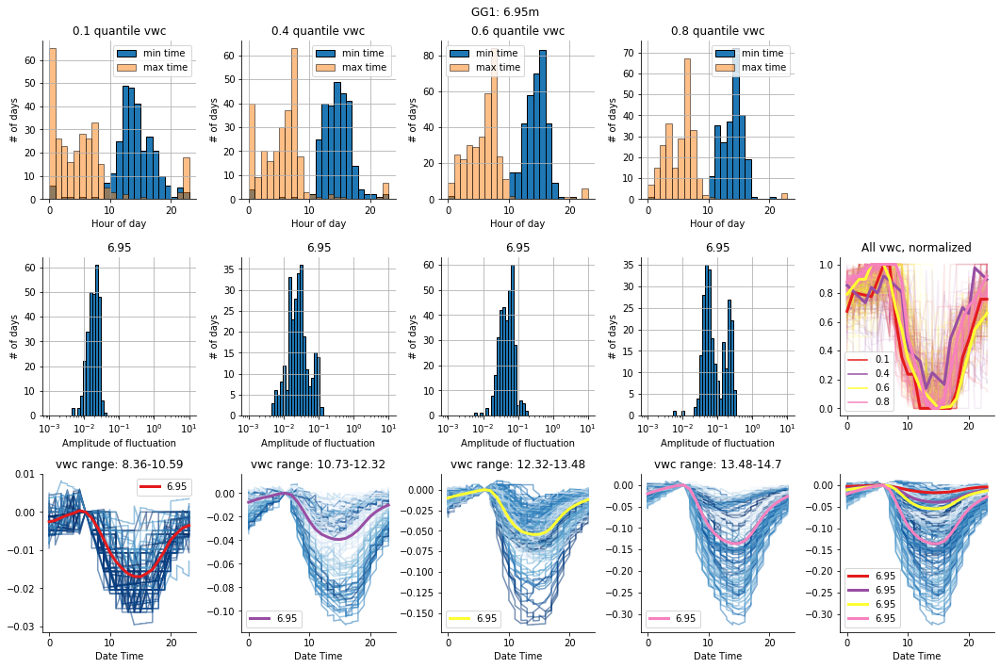

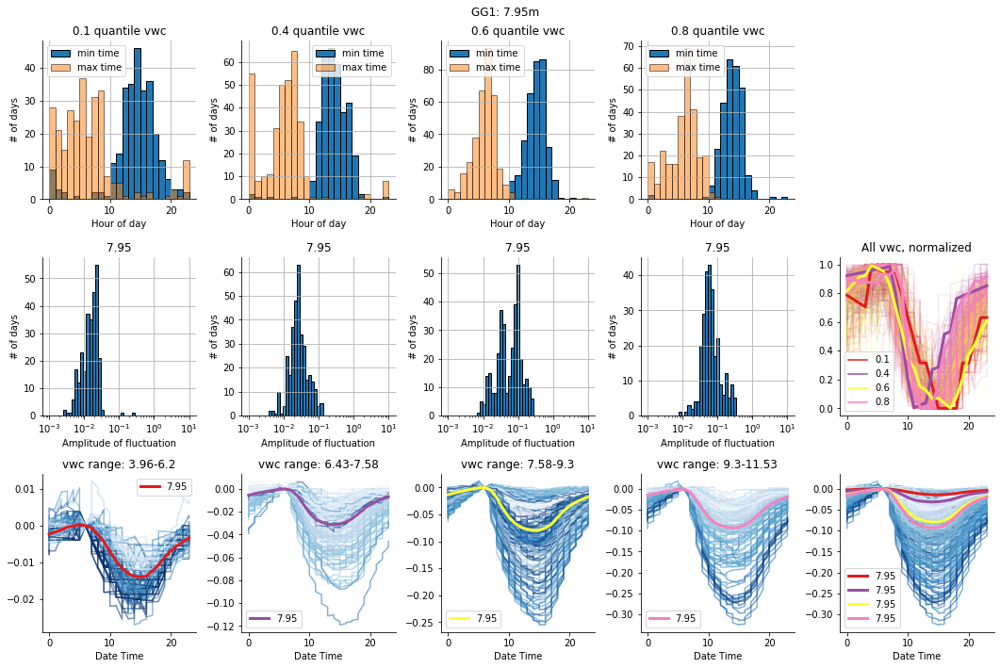

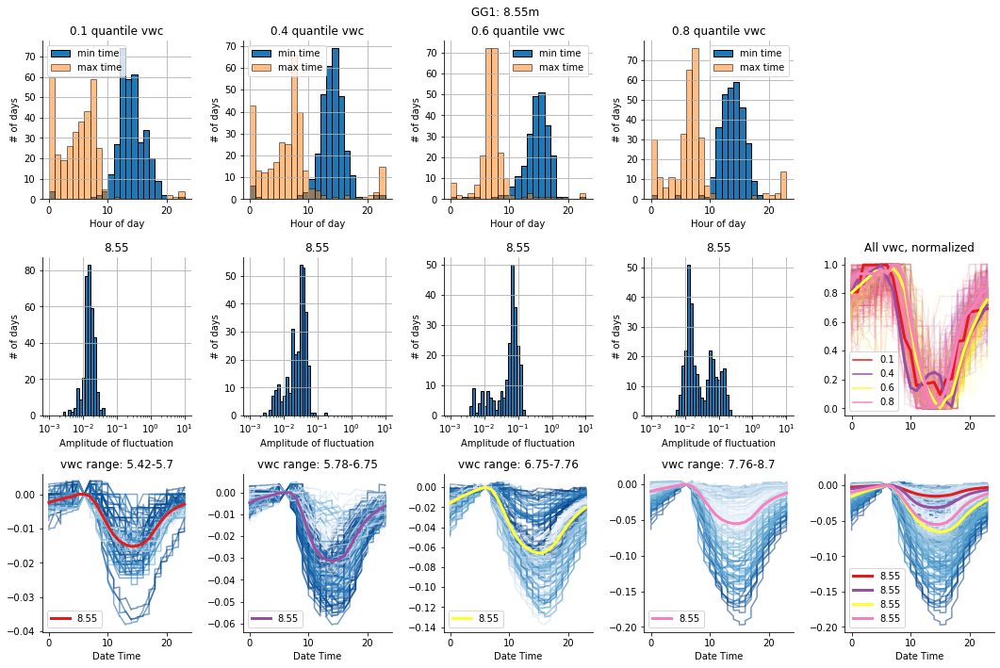

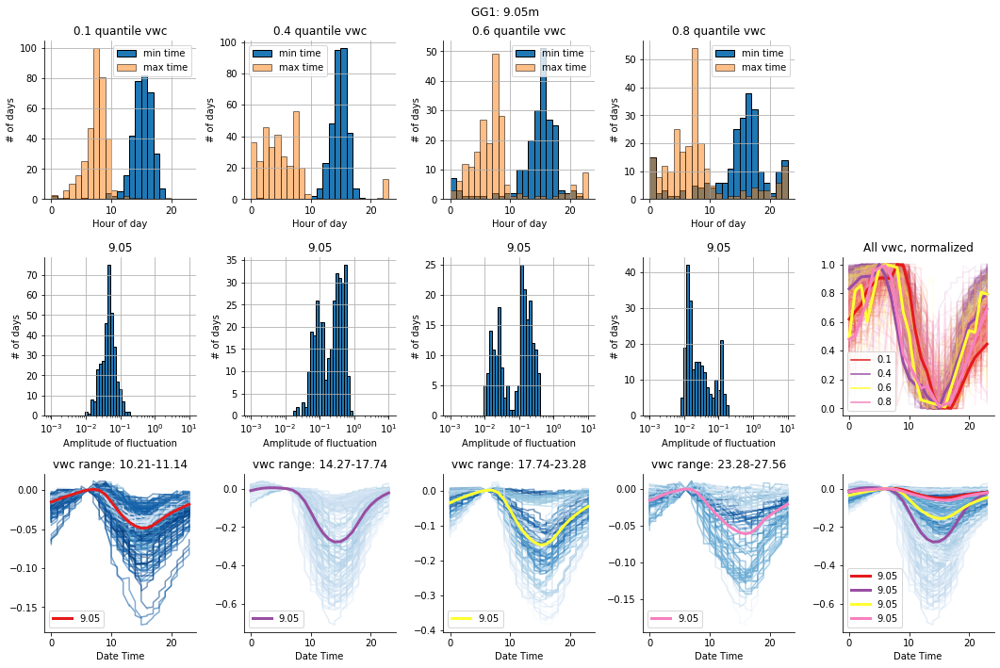

WP1


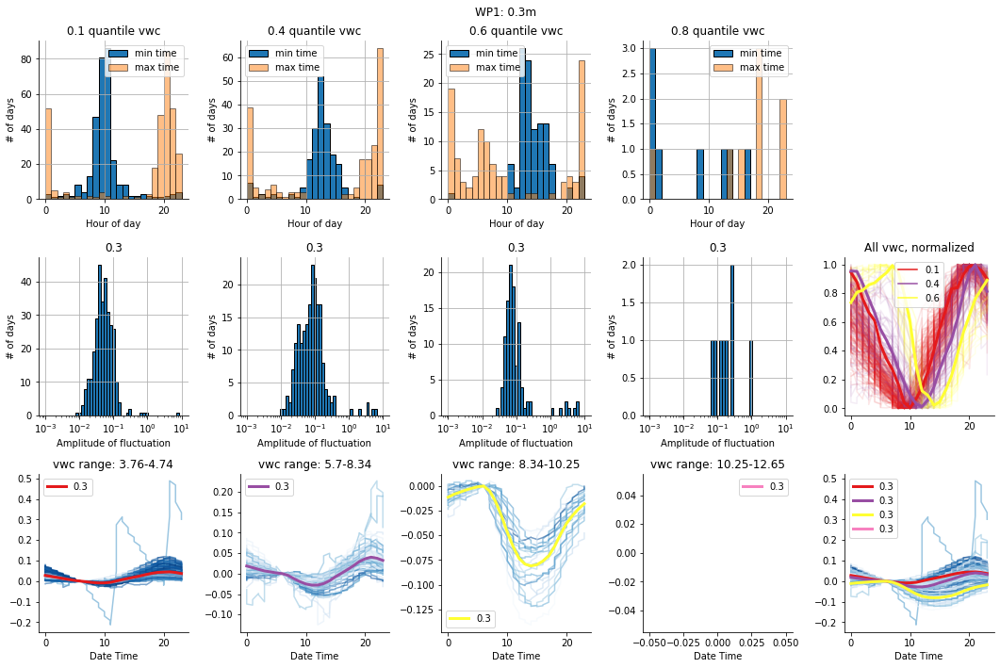

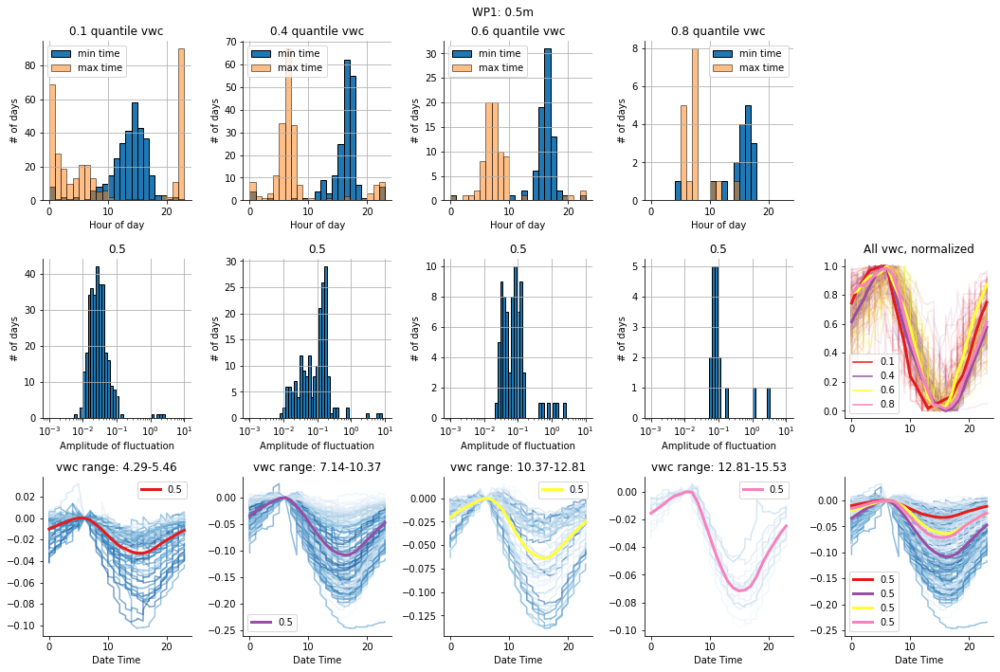

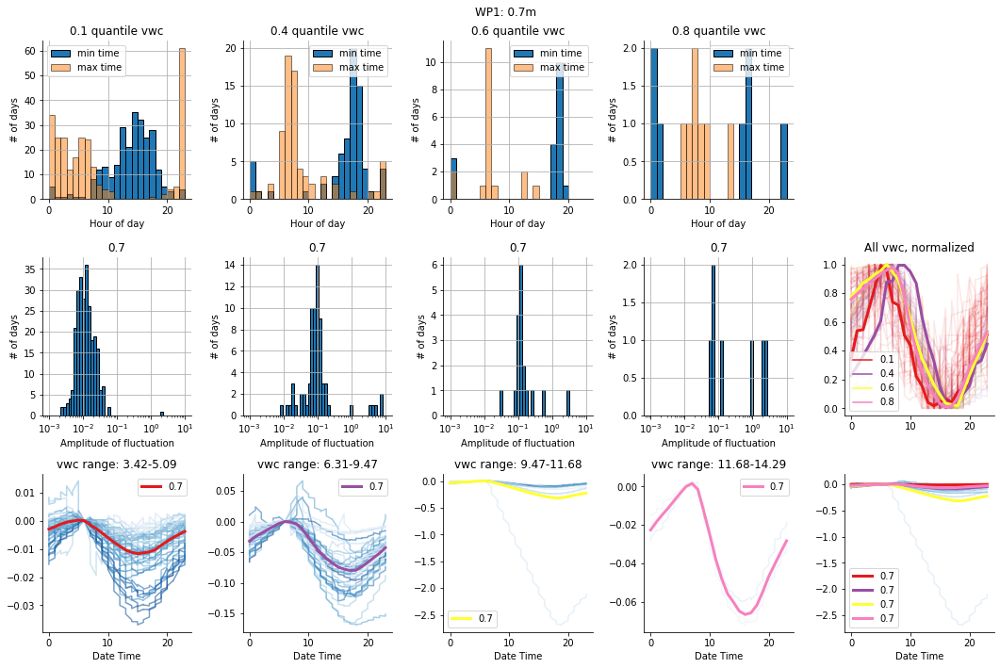

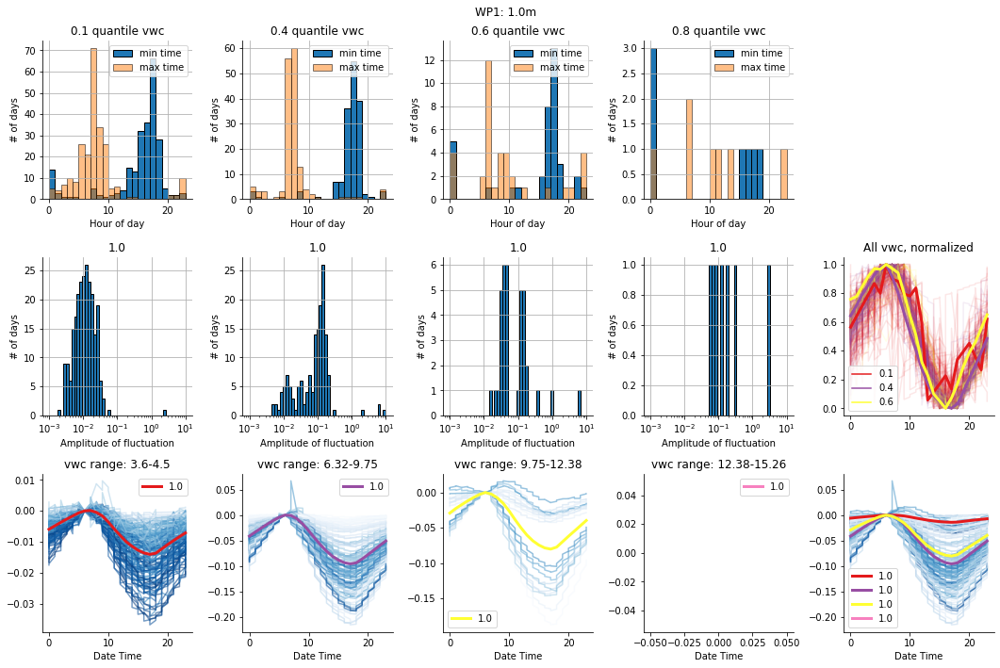

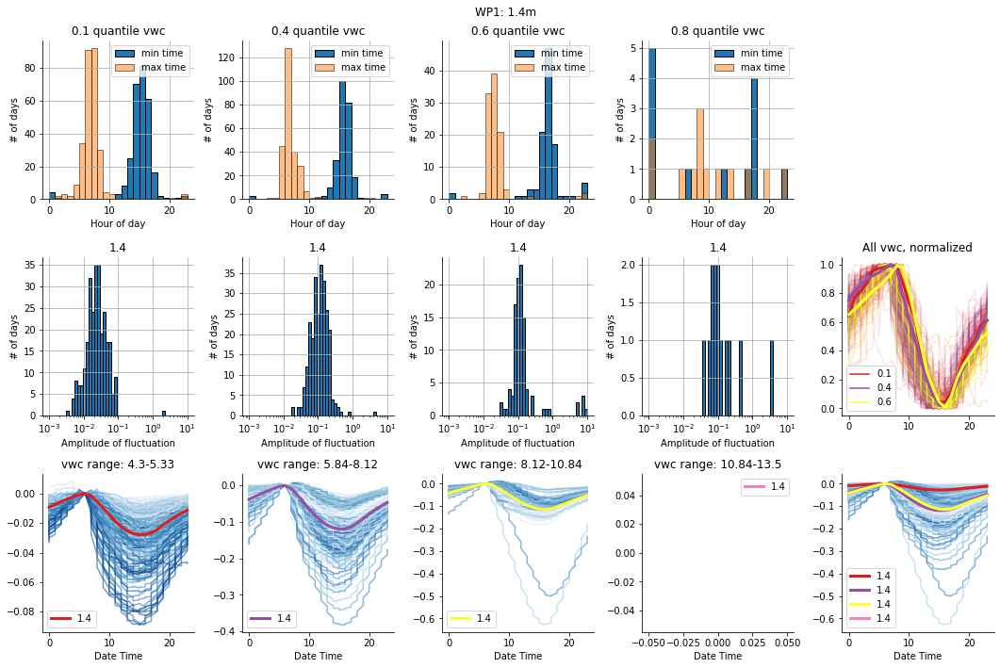

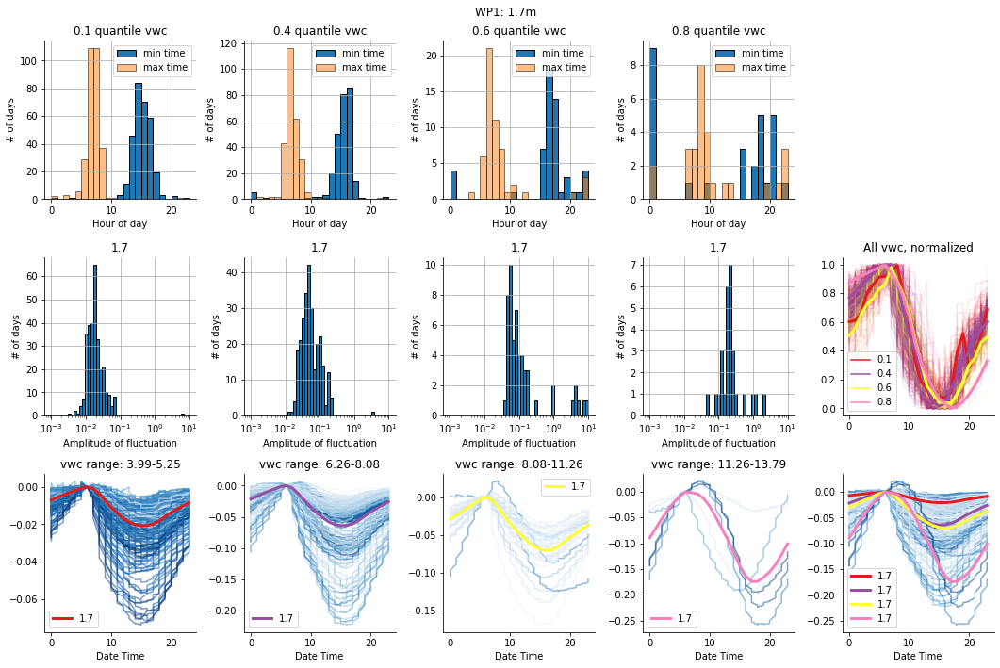

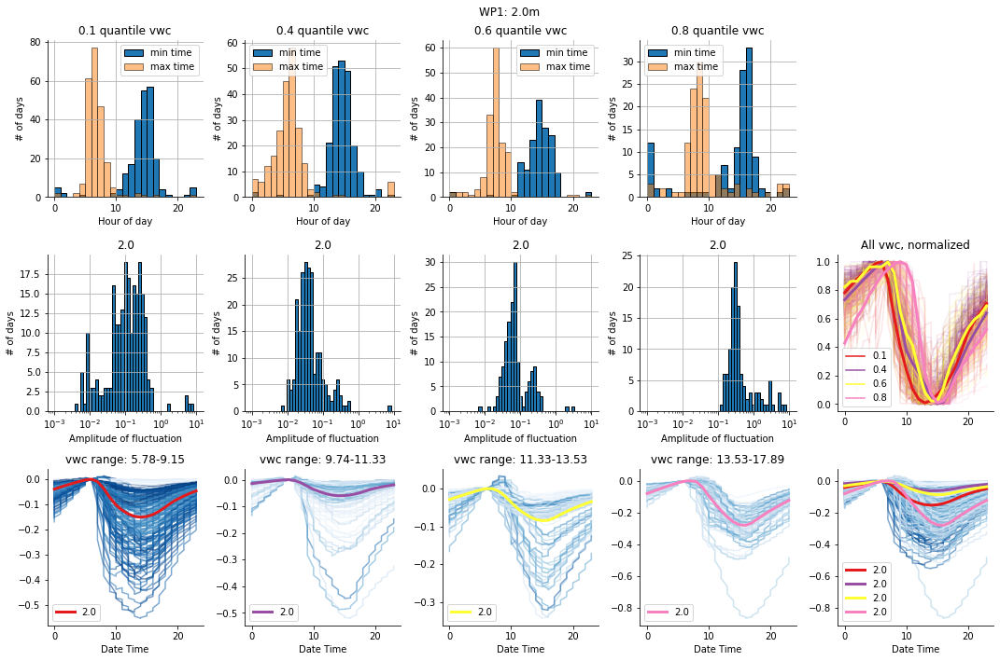

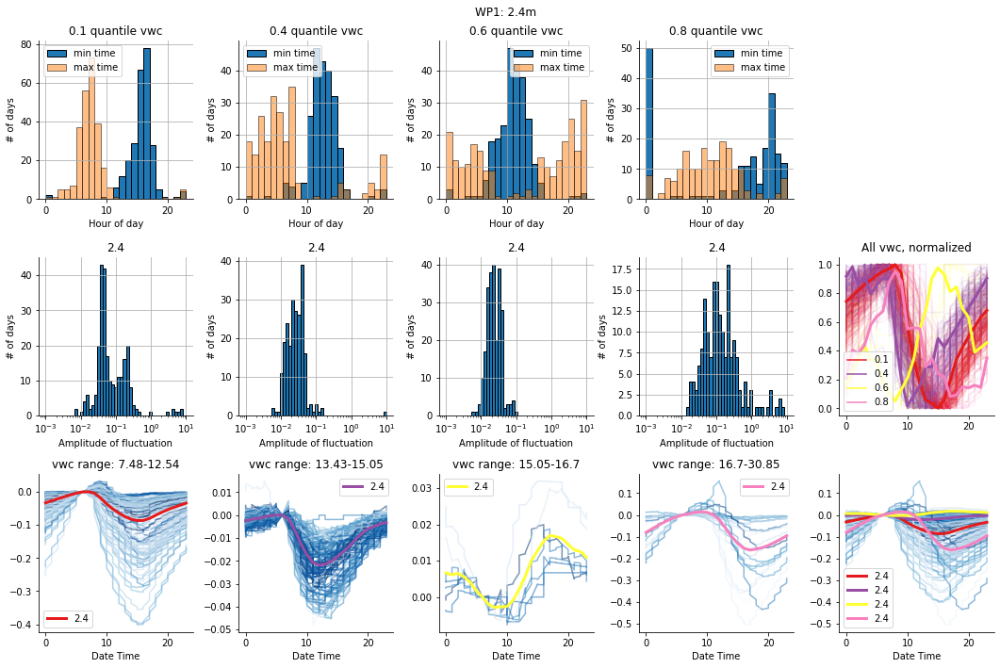

WP2


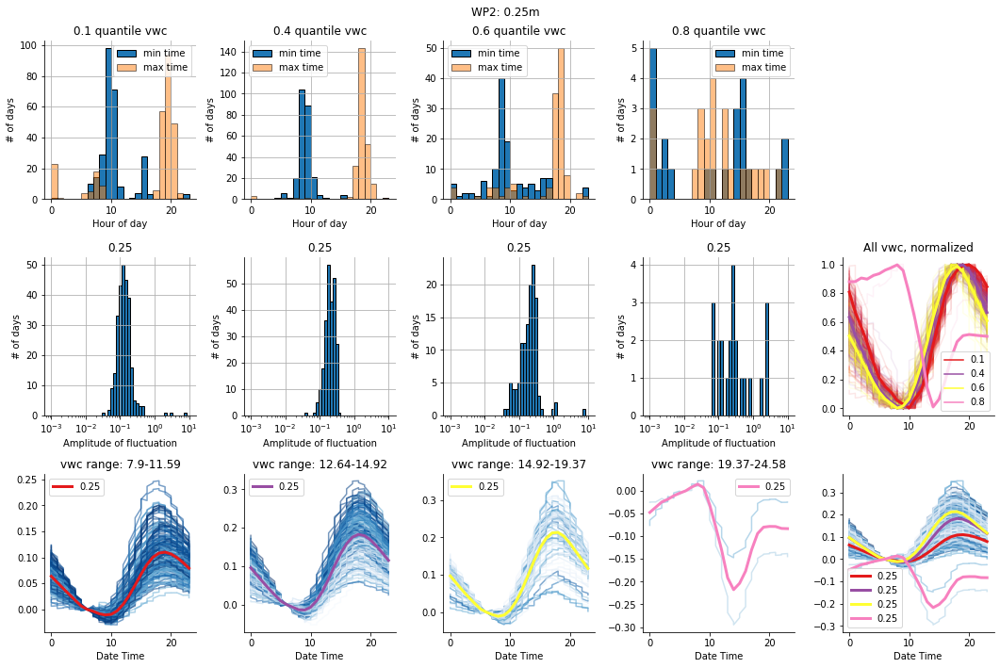

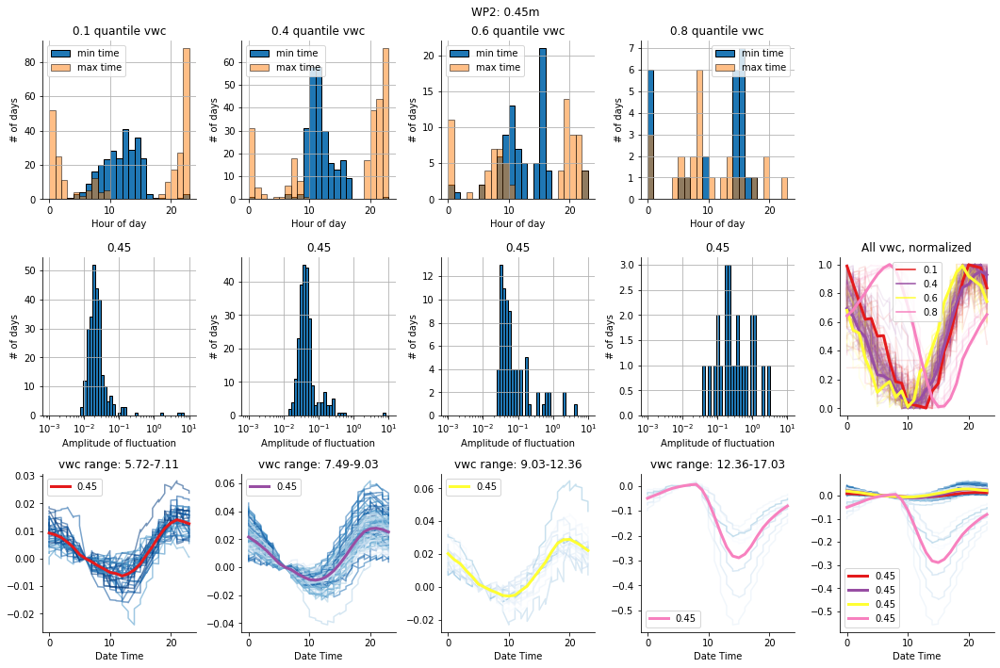

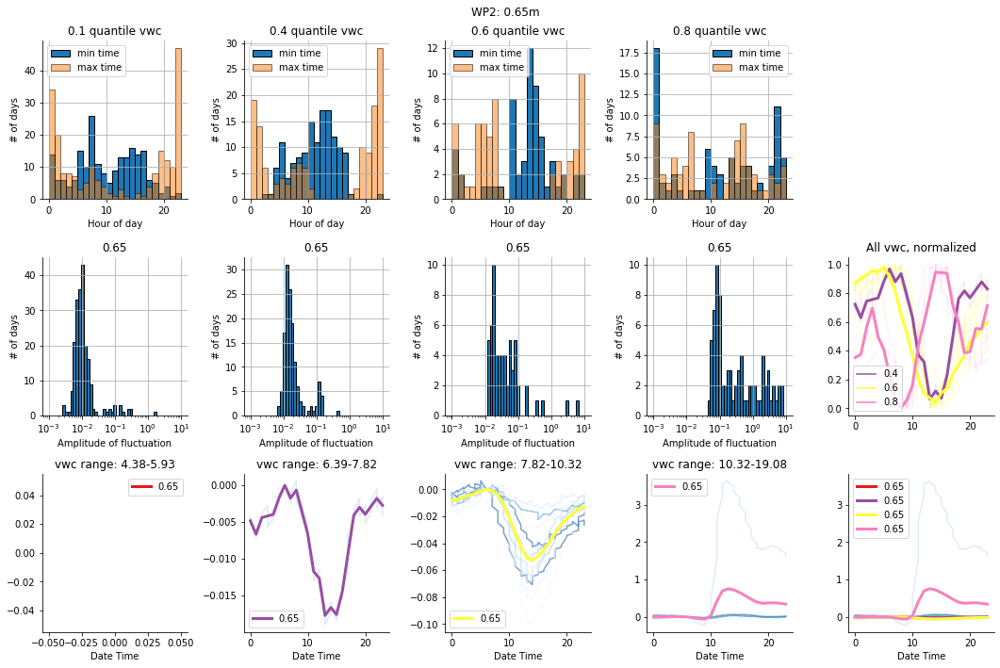

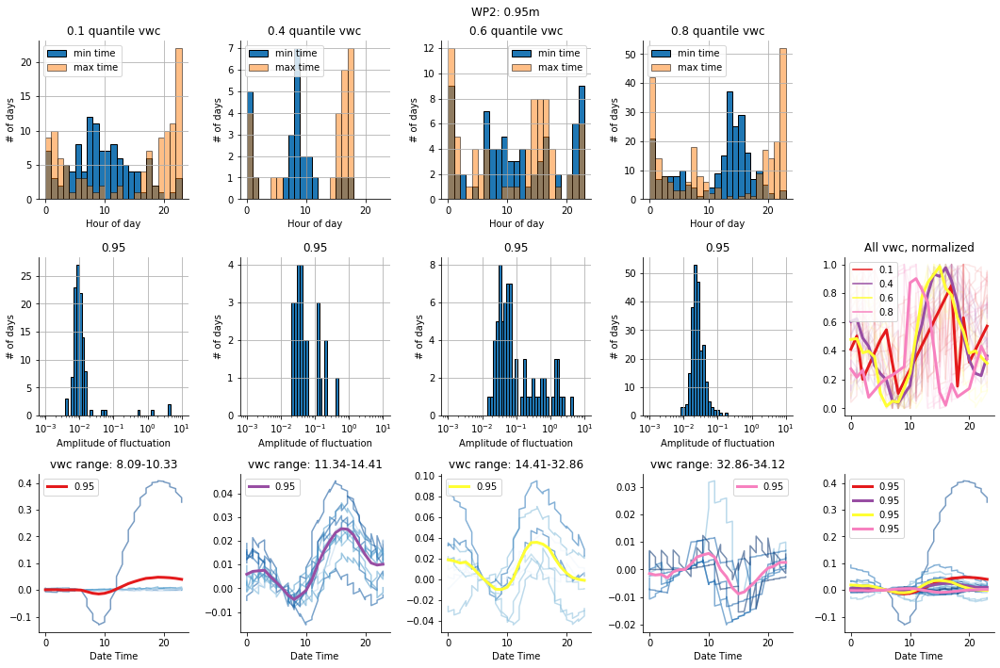

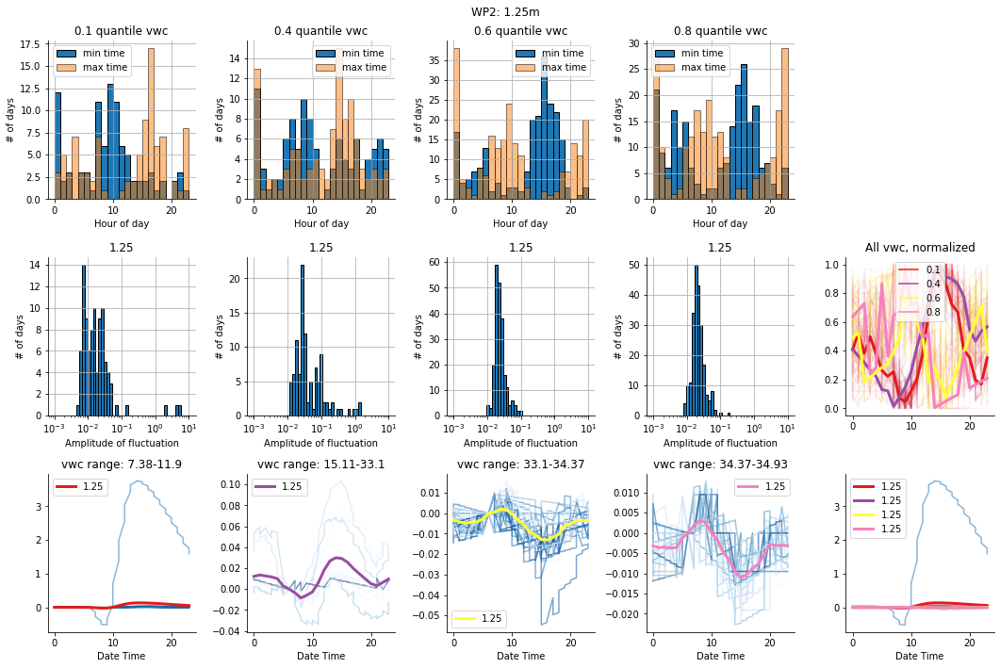

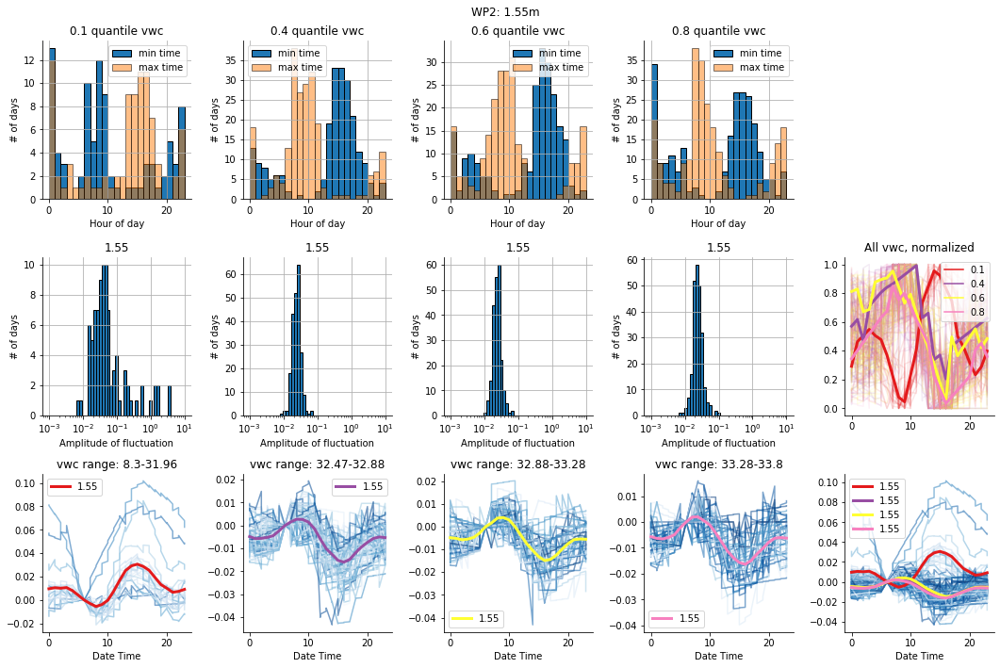

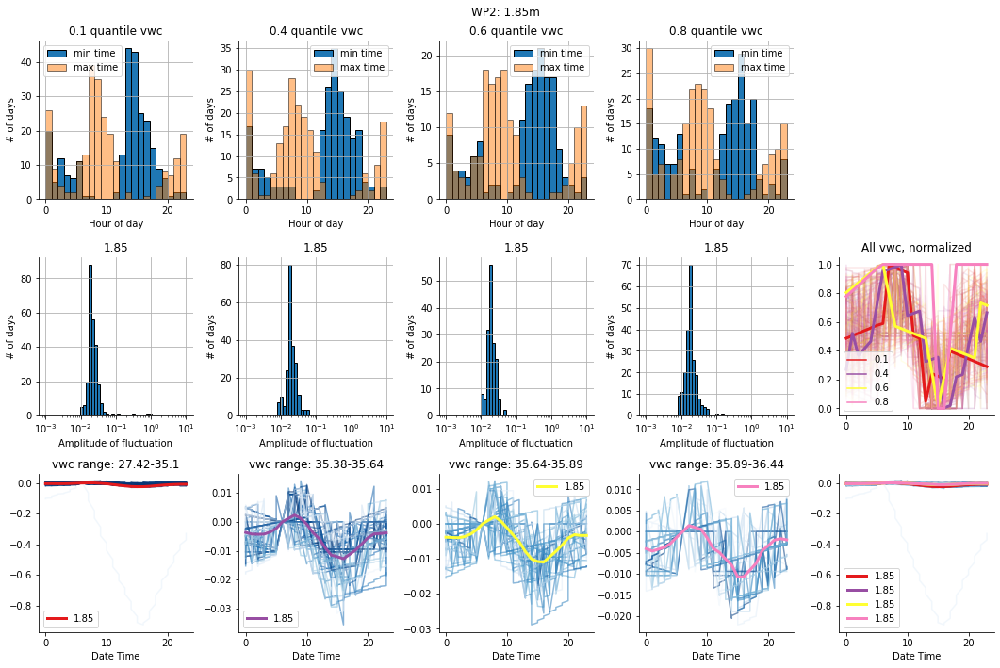

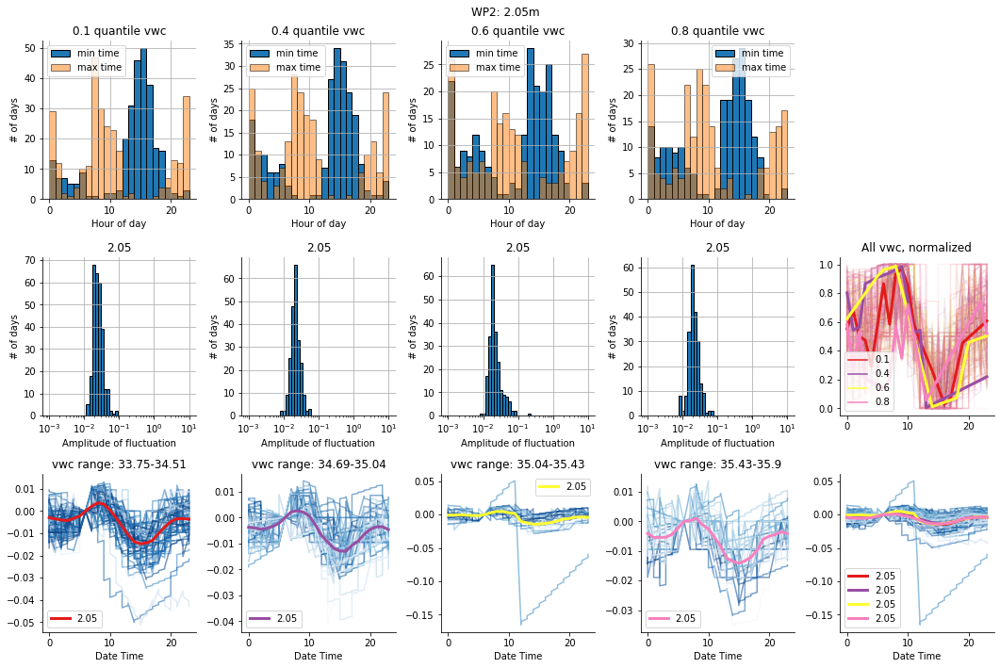

DD


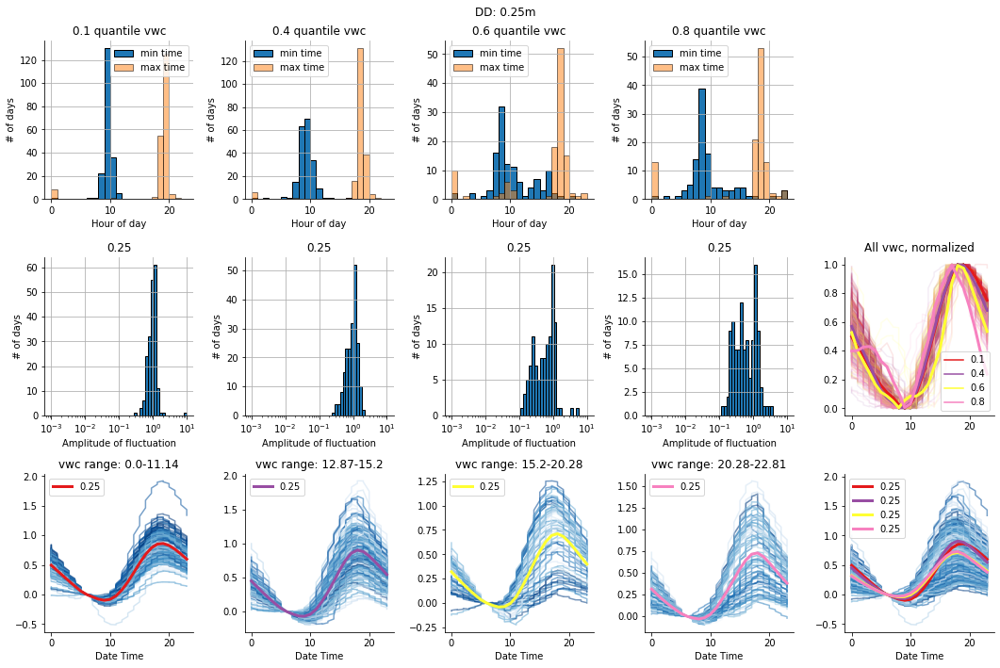

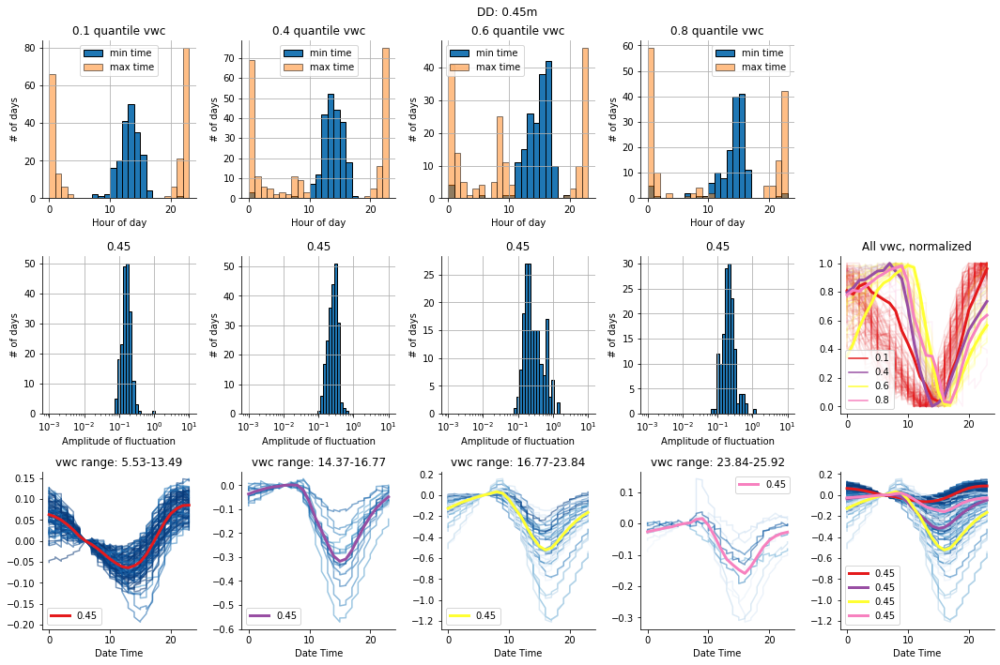

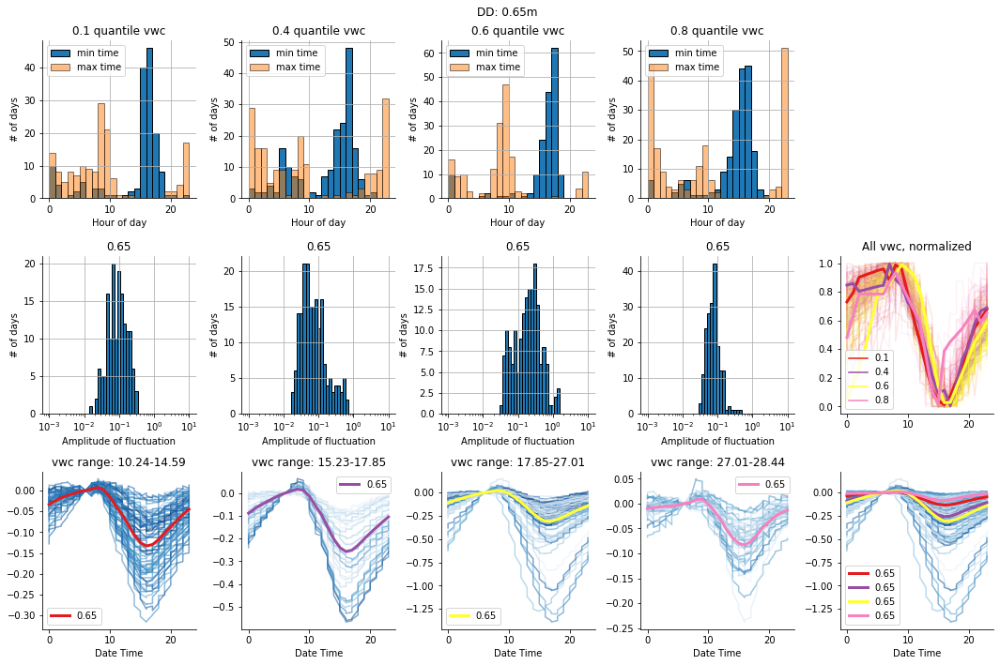

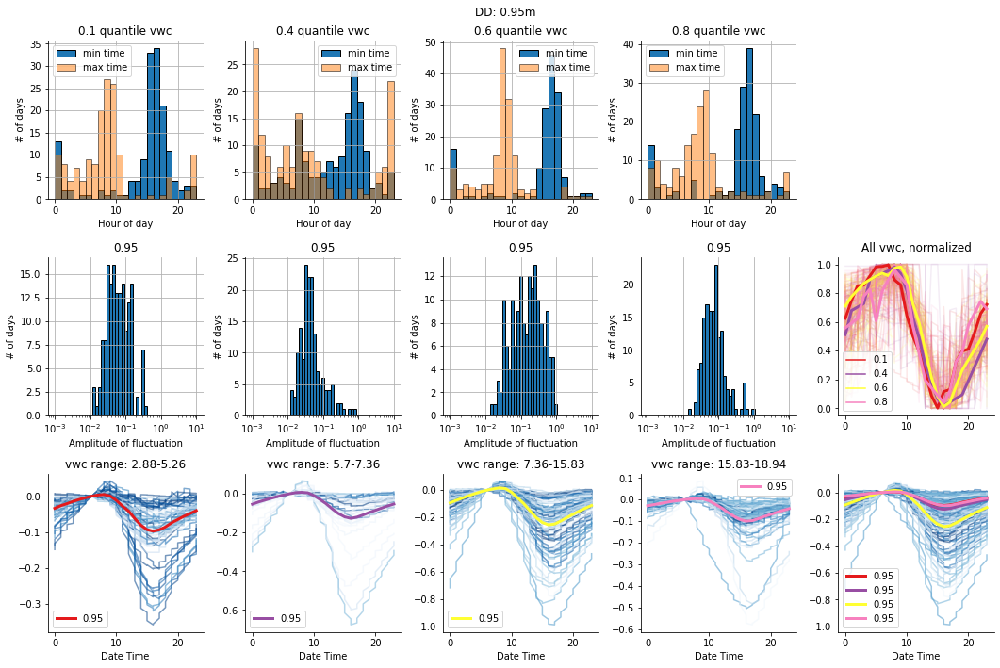

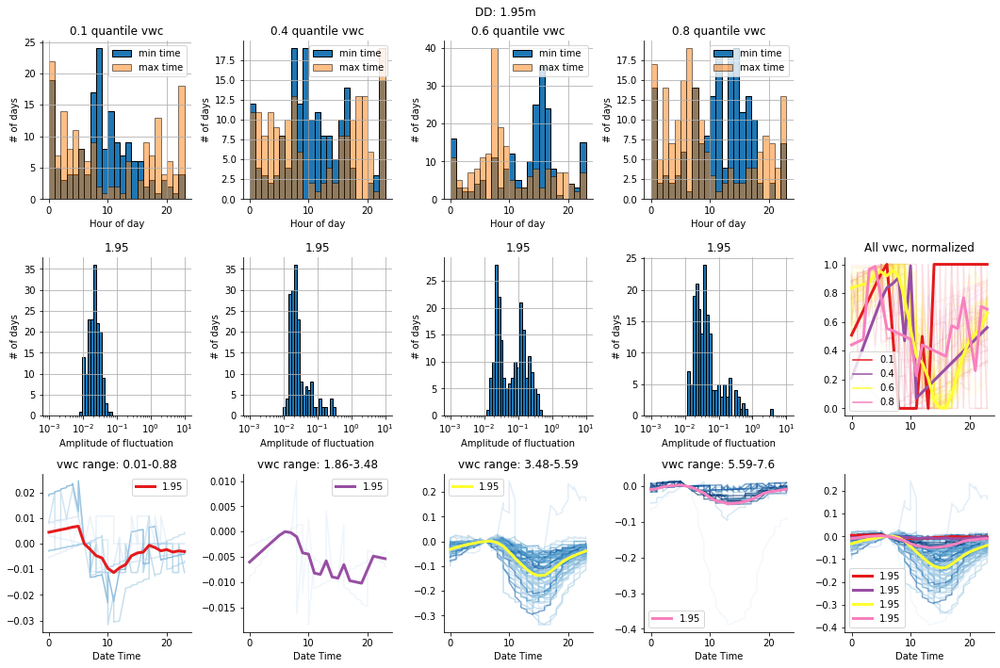

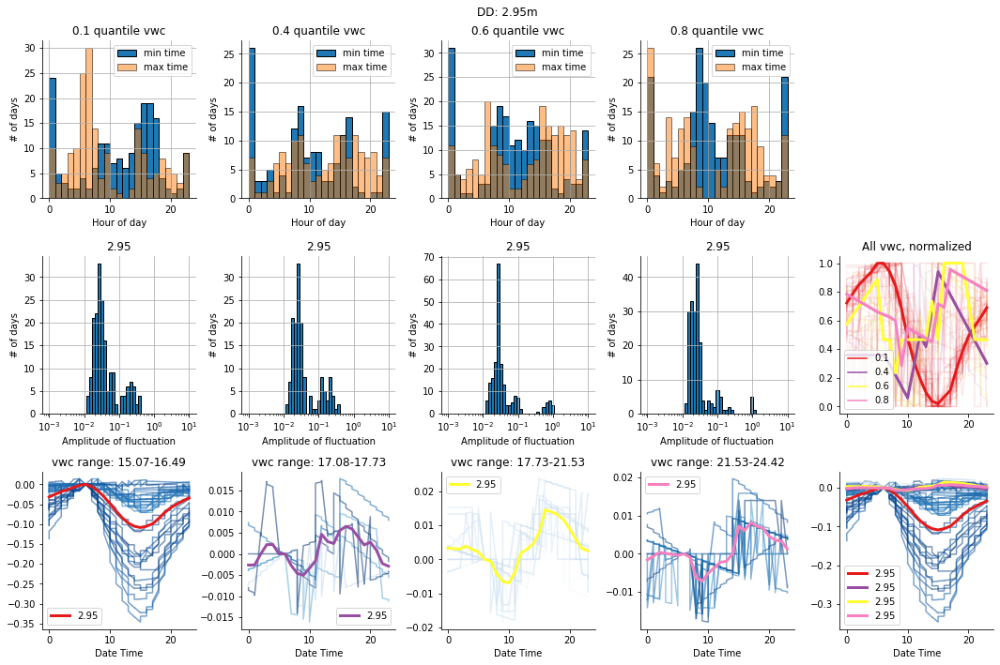

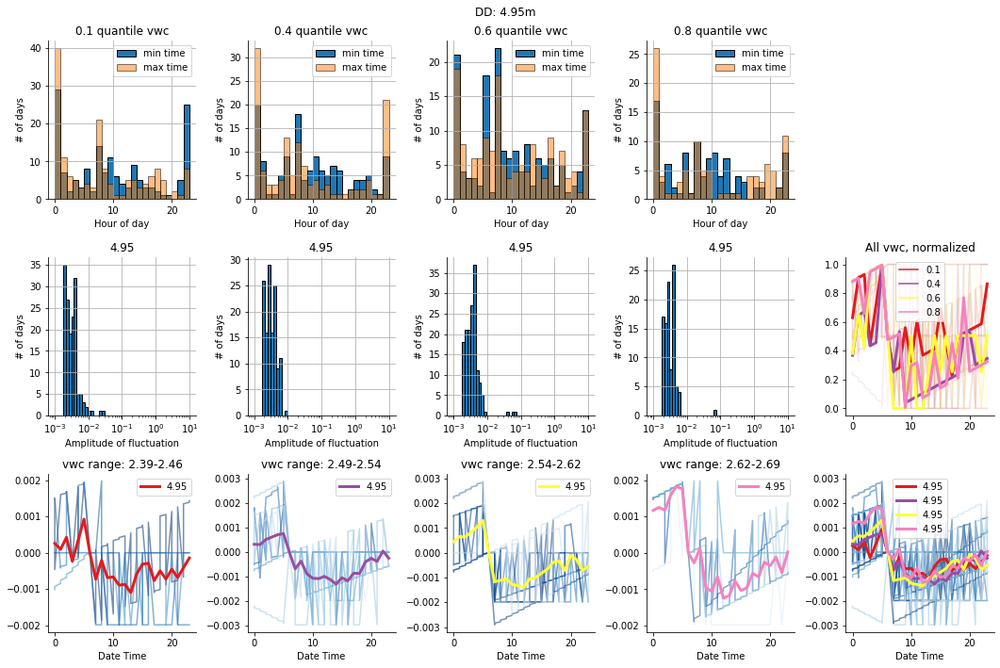

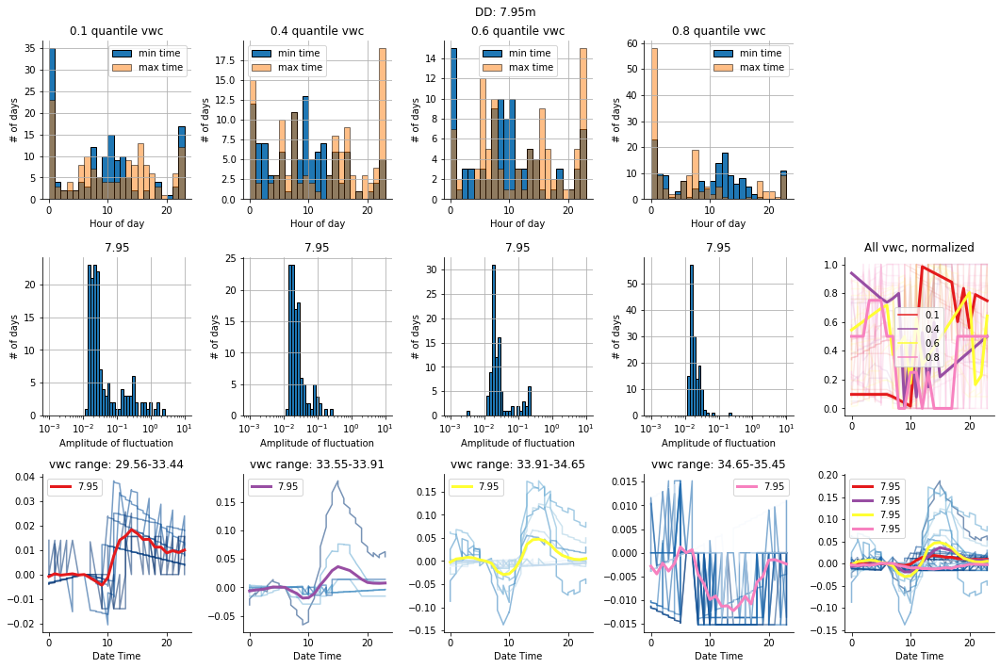

In [21]:
# this block analyzes
medmax = {site:{} for site in sites}    # median time of daily max [hrs]
medmin = {site:{} for site in sites}    # median time of daily min [hrs]
numnoinc = {site:{} for site in sites}  # number of days for each sensor with no moisture increase during day
noincdays = {site:{} for site in sites} # days for each sensor with no moisture increase during day


for site in sites[:]:
    print(site)
    sm = pd.read_csv('../Data/final_processed_data/vwc_simoneprocess_'+site+'.csv')
    sm['Date Time'] = pd.to_datetime(sm['Date Time'])
    sm.set_index('Date Time',inplace=True)
    sm['day'] = np.where(sm.index.hour<6,sm.index.dayofyear,sm.index.dayofyear+1)
    sm['year'] = sm.index.year
    sm = sm.resample('30min').mean()

    weather = pd.read_csv('../Data/final_processed_data/'+site+'_weather.csv')
    weather['Unnamed: 0'] = pd.to_datetime(weather['Unnamed: 0'])
    weather.set_index('Unnamed: 0',inplace=True)
    weather['Trolling'] = weather.air_temperature_C.rolling(48).mean()
    

    smstart = sm[sm.index.hour==6].resample('30min').first().interpolate()
    smdiff = sm.loc[max([sm.index.values[0],
                        weather.index.values[0]]):
                   min([sm.index.values[-1],
                       weather.index.values[-1]])]
    for col in smdiff.drop(columns=['day','year']).columns:
        smdiff[col] = smdiff[col]-smstart[col]
    smdiff = smdiff.dropna()
    sm = sm.dropna()
    depths = sm.columns
    depths = [d for d in depths if d not in ['day','year']]
    medmax[site] = {dep:{} for dep in depths}
    medmin[site] = {dep:{} for dep in depths}
    for dep in depths[:]:
        fig,axs = plt.subplots(3,5,figsize = (15,10))
        meancurves = {}
        for j,quant in enumerate([.1,.4,.6,.8][:]):
            lowd = sm[dep].quantile(quant-.1)
            highd = sm[dep].quantile(quant+.1)
            smsub1 = sm[(sm[dep].rolling(48).mean()>lowd)&
                        (sm[dep].rolling(48).mean()<highd)#&
                       ]
            smsub = smdiff[smdiff.index.isin(smsub1.index)][[dep]]
            
            smdec = sm.resample('H').mean().diff()
            smdec['date'] = smdec.index.date
            smdec = smdec[(smdec.index.hour>5)&(smdec.index.hour<20)]
            smdec = smdec[smdec[dep]>(0)]
            smdec = smdec.groupby(smdec.index.date)[dep].count()
            smdec = smdec.to_frame().merge(sm.groupby(sm.index.date).max()[dep],
                                           left_index=True,right_index=True,how='right')
            smdec = smdec.merge(weather.groupby(weather.index.date).rain_mm.sum(),
                                left_index=True, right_index=True)
            smdec = smdec.drop(columns=dep+'_y').fillna(0)
            numnoinc[site][dep] = len(smdec[(smdec[dep+'_x']==0)&
                                           (smdec.rain_mm<2)])
            noincdays[site][dep] = smdec[(smdec[dep+'_x']==0)&
                                        (smdec.rain_mm<2)].index
            
            
            sscount = smsub.groupby(smsub.index.date).count()

            sscount = sscount[sscount==48].reset_index()
            sscount['index'] = pd.to_datetime(sscount['index'])
            sscount.set_index('index',inplace=True)
            sscount = sscount.resample('D').first()
            # 1. Identify valid values
            is_valid = sscount[dep].notna()

            # 2. Increment group ID every time the validity changes (Valid -> NaN or NaN -> Valid)
            group_id = (is_valid != is_valid.shift()).cumsum()

            # 3. Count block sizes, and keep only valid rows in blocks larger than 1
            sscount = sscount[is_valid & (is_valid.groupby(group_id).transform('size') > 5)]

            smm = smsub[[dep]].reset_index()
            smm = smm[(smm['Date Time'].dt.date.isin(sscount.index.date))&
                     (smm['Date Time'].dt.date.isin(smdec[smdec[dep+'_x']>0].index))]
            smm = smm.set_index('Date Time')

            smmin = (smm.groupby(smm.index.date).idxmin()[dep].dt.hour)
            smmax = (smm.groupby(smm.index.date).idxmax()[dep].dt.hour)
            minmed = smmin.median()
            maxmed = smmax.median()
            
            medmin[site][dep][quant] = minmed
            medmax[site][dep][quant] = maxmed
            
            
            
            smamp = smm.groupby(smm.index.date).max()-smm.groupby(smm.index.date).min()
            
            ax = axs[0,j]
            bins = list(range(24))
            smmin.hist(label='min time',edgecolor ='k',ax=ax,bins = bins)
            smmax.hist(label='max time',edgecolor = 'k',alpha=.5,ax=ax,bins = bins)
            ax.legend()
            ax.set_xlabel('Hour of day')
            ax.set_ylabel('# of days')
            ax.set_title(str(quant)+' quantile vwc')
            
            ax = axs[1,j]
            smamp.hist(edgecolor = 'k',ax=ax,bins = np.logspace(-3,1))
            ax.set_xscale('log')
            ax.set_xlabel('Amplitude of fluctuation')
            ax.set_ylabel('# of days')

            smkeep = (((smmin-minmed)%24<3)|((minmed-smmin)%24<3)) & (((smmax-maxmed)%24<3)|((maxmed-smmax)%24<3))
            smkeep = smmax[smkeep].index

            smm = smm.reset_index()
            
            smm = smm[smm['Date Time'].dt.date.isin(smkeep)].set_index('Date Time')
            if len(smkeep)<10:
                medmax[site][dep][quant] = np.nan
                medmin[site][dep][quant] = np.nan

            meancurve = smm.groupby(smm.index.hour).mean()
            meancurves[quant] = meancurve

            ax1 = axs[1,-1]
            axs[1,-1].set_title('All vwc, normalized')
            first = True
            for ax in [axs[2,j],axs[2,-1]]:
                
                
                for date in set(smm.index.date):
                    cmap = mpl.colormaps['Blues']#hsv']
                    cmap1 = mpl.colormaps['Set1']
                    smmsub = smm[smm.index.date==date]
                    sss = smsub1[(smsub1[dep].index.date)==date][dep].mean()#-smsub1[dep].min()
                    
                    ax.plot(smmsub.set_index(smmsub.index.hour),alpha=0.55,
                            c=cmap((sss-lowd)/(highd-lowd)),#date.timetuple().tm_yday/365),
                           zorder = -1)
                    smmsub['norm'] = (smmsub[dep]-smmsub[dep].min())/(smmsub[dep].max()-smmsub[dep].min())
                    
                    if ax==axs[2,-1]:
                        label = None
                        if first:
                            label = quant
                            first = False
                            nn = smmsub[['norm']].groupby(smmsub.index.hour).mean()
                            ax1.plot(nn,c=cmap1(quant),lw=3)
                        else:
                            label = None
                        ax1.plot(smmsub.set_index(smmsub.index.hour)['norm'],
                             alpha=.1,c=cmap1(quant),label=label,zorder = -1)
                axs[-1,-1].set_title('all vwc together')
                        
                meancurve.plot(ax=ax,c=cmap1(quant),lw=3)
                ax.set_title('vwc range: '+str(round(lowd,2))+'-'+str(round(highd,2)))
            ax.set_title('')
            leg = ax1.legend()
            for legend_handle in leg.legend_handles:
                legend_handle.set_alpha(1.0)
            
            
            
        fig.suptitle(site+': '+str(dep)+'m')
        fig.tight_layout()
        for ax in axs.flatten():
            ax.spines[['top','right']].set_visible(False)
            
        axs[0,-1].axis('off')
        plt.show()

# Examine days that don't show the wave signature
These days have no increasing moisture content during the day. This excludes days with significant rainfall or drainage from above that would cover up a plant water use signature. It also excludes dates with no physical explanation for increasing soil moisture during the day, which could be caused by a variety of different sensor issues. Moisture increase due to hydraulic redistribution would happen at night, so nighttime increases in vwc are allowed for these dates and will be explored below.

In [22]:
# number of dates for each sensor when data show no increases during the day
numnoinc

{'GG1': {'0.25': 290,
  '0.45': 178,
  '0.65': 701,
  '0.85': 330,
  '1.05': 529,
  '1.55': 277,
  '1.95': 486,
  '2.55': 344,
  '2.95': 239,
  '3.95': 155,
  '4.95': 57,
  '5.95': 61,
  '6.95': 70,
  '7.95': 26,
  '8.55': 45,
  '9.05': 171},
 'WP1': {'0.3': 390,
  '0.5': 494,
  '0.7': 835,
  '1.0': 717,
  '1.4': 492,
  '1.7': 500,
  '2.0': 283,
  '2.4': 279},
 'WP2': {'0.25': 292,
  '0.45': 411,
  '0.65': 662,
  '0.95': 785,
  '1.25': 455,
  '1.55': 330,
  '1.85': 294,
  '2.05': 156},
 'DD': {'0.25': 11,
  '0.45': 13,
  '0.65': 114,
  '0.95': 200,
  '1.95': 172,
  '2.95': 144,
  '4.95': 356,
  '7.95': 368}}

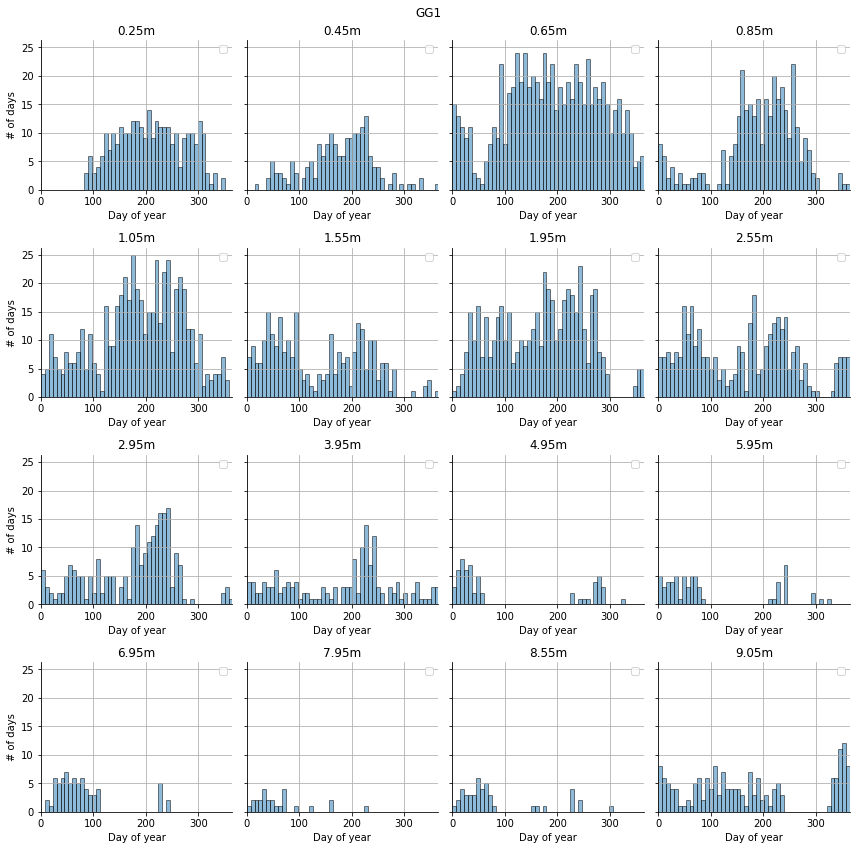

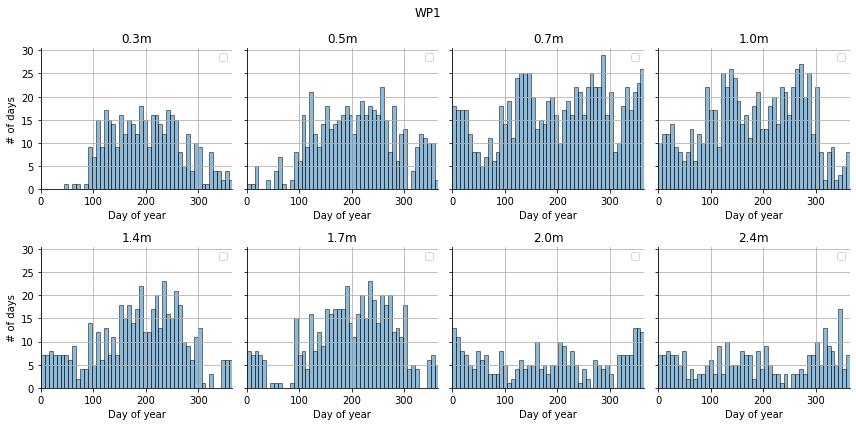

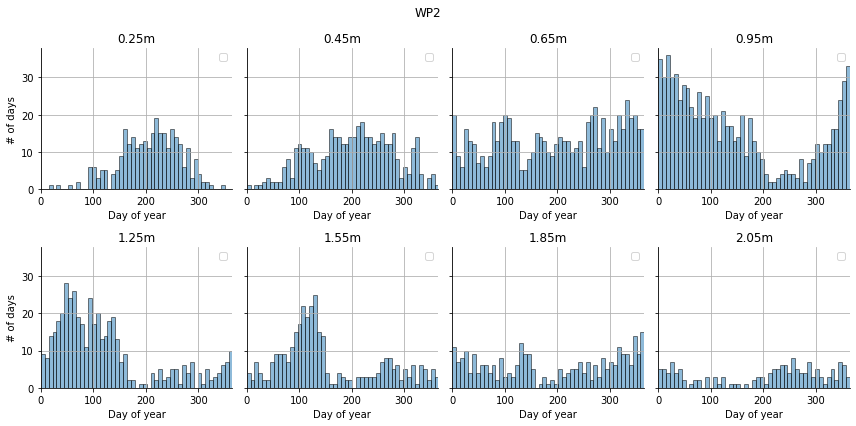

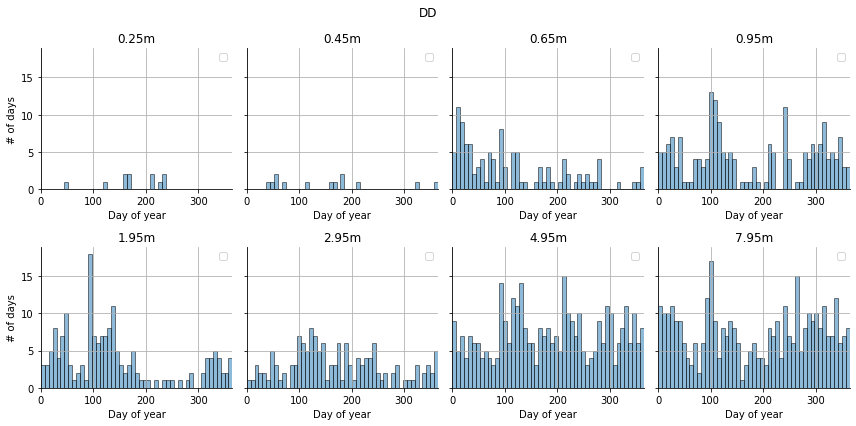

In [36]:
# look at distribution throughout year of dates when we have a signal
for site in sites:
    fig,axs = plt.subplots(int(len(numnoinc[site].keys())/4),4,
                       figsize = (12,3*len(numnoinc[site].keys())/4),
                          sharey=True)
    for k,dep in enumerate(list(numnoinc[site].keys())[:]):
        sm = pd.read_csv('../Data/final_processed_data/vwc_simoneprocess_'+site+'.csv')
        sm['Date Time'] = pd.to_datetime(sm['Date Time'])
        sm.set_index('Date Time',inplace=True)
        sm['day'] = np.where(sm.index.hour<6,sm.index.dayofyear,sm.index.dayofyear+1)
        sm['year'] = sm.index.year
        sm = sm.resample('15min').mean()

        weather = pd.read_csv('../Data/final_processed_data/'+site+'_weather.csv')
        weather['Unnamed: 0'] = pd.to_datetime(weather['Unnamed: 0'])
        weather.set_index('Unnamed: 0',inplace=True)
        weather['Trolling'] = weather.air_temperature_C.rolling(48).mean()
        weather['date'] = weather.index.date
        
        keepdays = noincdays[site][dep]
        
        sm['date'] = sm.index.date
        smn = sm[sm.date.isin(keepdays)].dropna()[[dep]]
        smb = sm[~(sm.date.isin(keepdays))].dropna()[[dep]]
        weather['inc'] = np.where(weather.date.isin(keepdays),1,0)
        
        
        weather['doy'] = weather.index.dayofyear
        for i,tab in enumerate(['doy',]):
            ax = axs.flatten()[k]
            for j in [1]:#range(2):
                wsub1 = weather.copy()
                wsub1 = wsub1[[tab,'inc']].resample('D').mean()
                wsub = wsub1[wsub1.inc==j]
                bins = np.linspace(0,wsub1[tab].max())
                wsub[tab].hist(ax=ax,edgecolor = 'k',bins=bins,
                                             alpha=.5,
                              label = None)
                if j==1:
                    ax.set_title(dep+'m')
                ax.set_xlabel(tab)
                ax.spines[['top','right']].set_visible(False)
                ax.set_xlabel('Day of year')
                ax.set_xlim(0,365)
                if k%4==0:
                    ax.set_ylabel('# of days')
            ax.legend()
    fig.suptitle(site)
    fig.tight_layout() 
    plt.show()

WP1
0.3
2022-04-09
2022-04-11


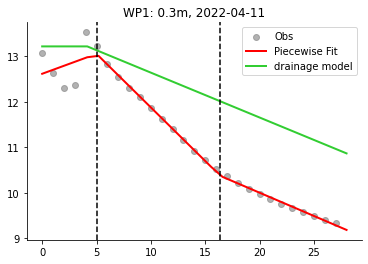

2022-04-12
2022-04-13
2022-04-14
2022-04-15


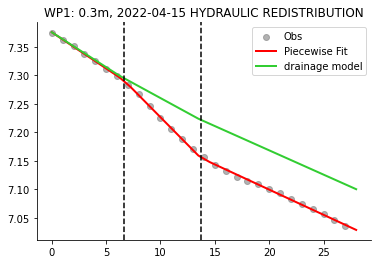

2022-04-16


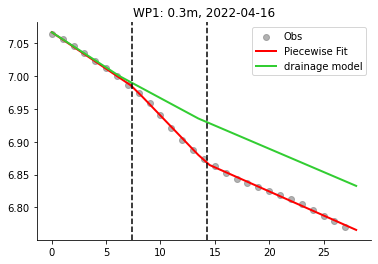

2022-04-17


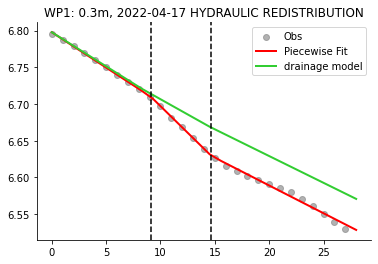

2022-04-18
2022-04-19


In [49]:
# # this block walks through every date with no increases during the day
# # at each sensor and fits a segmented regression. I assume that real
# # plant water use looks like a steeper decreasing slope during the
# # daytime. I exclude dates that don't look like this from further
# # analysis. I visualized here a few of the dates so you can see what
# # the script is doing. This block takes a while to run, so I saved 
# # the outputs. You probably don't want to run it yourself.
# # distance between green and red lines at end of day is inferred
# # plant water use. Dashed lines mark break points in data slope,
# # which correspond to onset and stop of plant water use each day.
# # I assigned hydraulic redistribution codes for each date. 0 means no
# # clear evidence of hydruliac redistribution. 1 means that there is
# # an overall increasing trend in vwc at night only that is plausibly
# # explained by hydraulic redistribution. 2 means that there is a temporary
# # increase in vwc at around 8pm-midnight that merits further investigation.

# sites = []
# depths = []
# dates = []
# plantstarts = []
# plantstops = []
# drainstarts = []
# inferreduse = []
# slopedrains1 = []
# slopedrains0 = []
# slopeplants = []
# hydrauldist = []

# for site in sites:
#     print(site)
#     for k,dep in enumerate(list(numnoinc[site].keys())[:]):
#         print(dep)
#         sm = pd.read_csv('../Data/final_processed_data/vwc_simoneprocess_'+site+'.csv')
#         sm['Date Time'] = pd.to_datetime(sm['Date Time'])
#         sm.set_index('Date Time',inplace=True)
#         sm['day'] = np.where(sm.index.hour<6,sm.index.dayofyear,sm.index.dayofyear+1)
#         sm['year'] = sm.index.year
#         sm = sm.resample('15min').mean()

#         weather = pd.read_csv('../Data/final_processed_data/'+site+'_weather.csv')
#         weather['Unnamed: 0'] = pd.to_datetime(weather['Unnamed: 0'])
#         weather.set_index('Unnamed: 0',inplace=True)
#         weather['Trolling'] = weather.air_temperature_C.rolling(48).mean()
#         weather['date'] = weather.index.date
        
#         keepdays = noincdays[site][dep]
        
#         sm['date'] = sm.index.date
#         smn = sm[sm.date.isin(keepdays)].dropna()[[dep]]
#         smb = sm[~(sm.date.isin(keepdays))].dropna()[[dep]]
        
#         for j,date in enumerate(keepdays[:]):
#             print(date)
#             smnsub1 = sm[(sm.index.date==date-datetime.timedelta(0))|
#                         (sm.index.date==date+datetime.timedelta(1))][[dep]]

#             smnsub = smnsub1.resample('H').mean().diff().abs()
#             smnsub1 = smnsub1.resample('H').mean()

#             x = list(range(28))
#             y = smnsub1[dep].values.flatten()[:28]

#             try:
#                 # 2. Initialize the piecewise linear fit object
#                 my_pwlf = pwlf.PiecewiseLinFit(x, y)

#                 # 3. Fit the model by specifying the number of line segments you want (e.g., 2 segments)
#                 # This will automatically find the best breakpoint location.
#                 breakpoints = my_pwlf.fit(3)

#                 # 4. Predict values for plotting
#                 x_hat = np.linspace(0, len(x), len(x))
#                 y_hat = my_pwlf.predict(x_hat)

#                 # 5. Extract slopes (gradients) for each segment
#                 slopes = my_pwlf.calc_slopes()

#                 non = False
#                 if breakpoints[2]<10:
#                     non = True
# #                     print('rats')
#                     continue
#                 elif (slopes[1])>(slopes[0]):
#                     non = True
#                     continue
#                 elif breakpoints[2]-breakpoints[1]<5:
#                     non = True
#                     continue
#                 elif abs(slopes[2])>abs(slopes[1])*.9:
#                     continue




#                 if slopes[0]>0:
#                     dslope = slopes[2]
#                     dmodel = [(y[round(breakpoints[1])])]*round(breakpoints[1])
#                 else:
#                     if slopes[2]>0:
#                         dslope = slopes[0]
#                     else:
#                         dslope = np.mean([slopes[0],slopes[2]])
#                     dmodel = [y_hat[0]+x*slopes[0] for x in range(round(breakpoints[1]))]
#                 dmodel = dmodel + [dmodel[-1]+dslope*(x-round(breakpoints[1])+1) for x in range(round(breakpoints[1]),
#                                                                      round(breakpoints[2]))]
#                 dmodel = dmodel + [dmodel[-1]+slopes[2]*(x-round(breakpoints[2])+1) for x in range(round(breakpoints[2]),
#                                                                          len(x_hat))]
#                 inferred_wateruse = dmodel[-1]-y_hat[-1]
#                 hydraulicredist = 0
#                 ydiff = y-y_hat
#                 ydiff1 = ydiff[round(breakpoints[2]):]
#                 maxind = list(ydiff1).index(max(ydiff1))

#                 if (slopes[0]>0) & (slopes[2]>0):
#                     non = True
#                     dmodel = [np.nan]*len(x_hat)
#                     inferred_wateruse = y[round(breakpoints[1])]-y[round(breakpoints[2])]
#                     hydraulicredist = 1
#                 elif np.mean(ydiff1[maxind-1:maxind+2])>np.mean(ydiff1[1:maxind-1])*2:
#                     hydraulicredist = 2

# #                 # 6. Visualize the result
# # #                 if (j<10)&(float(dep)<0.5):
# #                 fig,ax = plt.subplots(1,figsize = (6,4))
# #                 plt.scatter(x, y, color='gray', alpha=0.6, label='Obs')
# #                 plt.plot(x_hat, y_hat, color='red', linewidth=2, label='Piecewise Fit')
# #                 plt.plot(x_hat[:len(dmodel)],dmodel,
# #                     color = 'limegreen',linewidth = 2, label = 'drainage model')
# #                 for i in range(1,len(breakpoints)-1):
# #                     plt.axvline(breakpoints[i], color='k', linestyle='--', label=None)
# #                 ax.spines[['top','right']].set_visible(False)

# #                 plt.legend()

# #                 if hydraulicredist>0:
# #                     l = ' HYDRAULIC REDISTRIBUTION'
# #                 else:
# #                     l = ''
# #                 plt.title(site+': '+str(dep)+'m, '+str(date)+l)
# #                 plt.show()

#                 sites.append(site)
#                 depths.append(dep)
#                 dates.append(date)
#                 plantstarts.append(breakpoints[1])
#                 plantstops.append(breakpoints[2])
#                 slopedrains0.append(slopes[0])
#                 slopeplants.append(slopes[1])
#                 slopedrains1.append(slopes[2])
#                 inferreduse.append(inferred_wateruse)
#                 hydrauldist.append(hydraulicredist)
#             except:
#                 continue
            
            
# # wateruse = pd.DataFrame.from_dict({'site':sites,
# #                                      'depth':depths,
# #                                      'date':dates,
# #                                      'plantstarthr':plantstarts,
# #                                      'plantstophr':plantstops,
# #                                    'slopedrain0':slopedrains0,
# #                                    'slopeplant':slopeplants,
# #                                    'slopedrain1':slopedrains1,
# #                                      'inferred_water_use':inferreduse,
# #                                    'hydraulic_redistribution':hydrauldist
# #                                   })

# # wateruse.to_csv('../Data/wateruse10082026.csv')

In [52]:
# import data from the outputs of above block
wateruse = pd.read_csv('../Data/wateruse10082026.csv').drop(columns='Unnamed: 0')

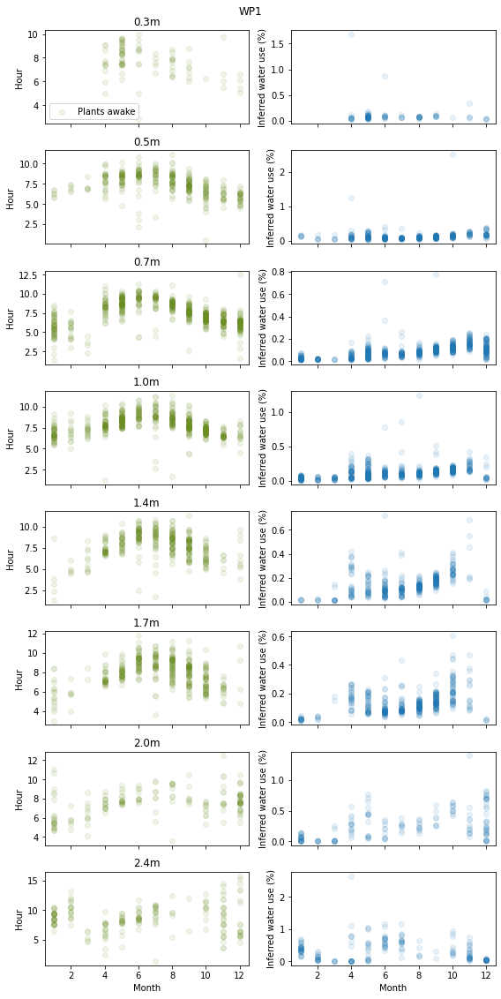

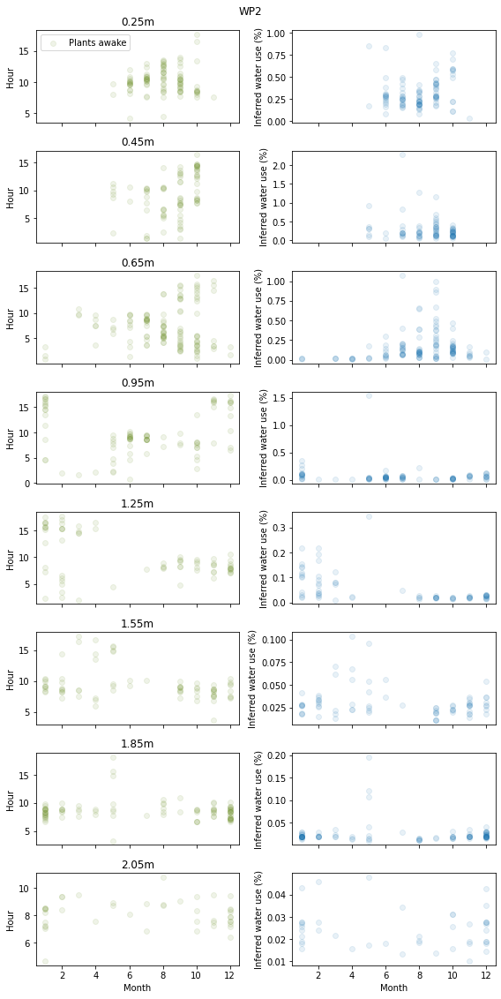

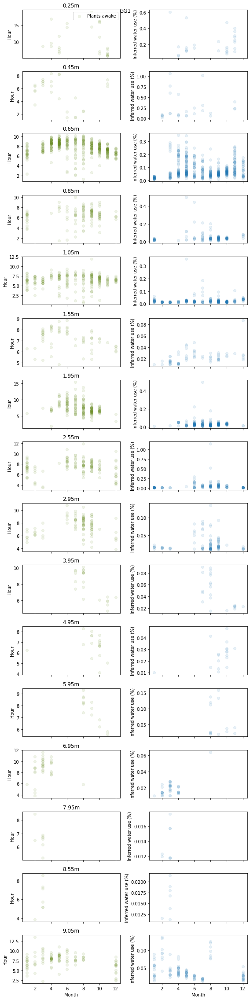

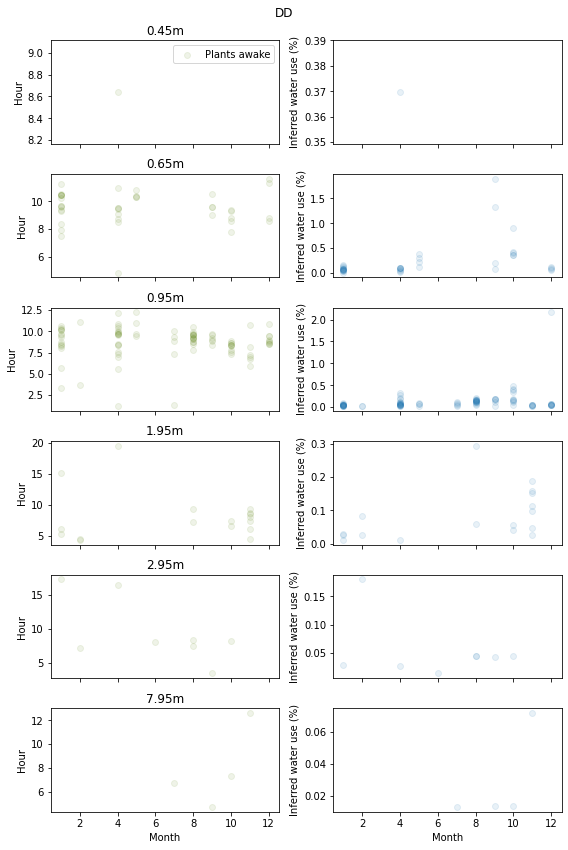

In [55]:
# overview of water use findings for each sensor with annual 
# patterns and daily timing throughout the year

ww = wateruse[wateruse.inferred_water_use>0.01]
ww['datetime'] = pd.to_datetime(ww['date'])
for site in ww.site.unique():
    wwsub = ww[ww.site==site].set_index('datetime')
    fig,axs = plt.subplots(len(wwsub.depth.unique()),2,
                          figsize = (8,2*len(wwsub.depth.unique())),sharex=True)
    for i,dep in enumerate(wwsub.depth.unique()):
        wwsub1 = wwsub[wwsub.depth==dep]
        wwsub1['month'] = wwsub1.index.month
        ax = axs[i,0]
        ax.scatter(wwsub1.month,wwsub1.plantstarthr,alpha=.1,
                   c='olivedrab',label = 'Plants awake')
        
        ax.set_ylabel('Hour')
        ax.set_title(str(dep)+'m')
        if i==0:
            ax.legend()
        if i==len(wwsub.depth.unique())-1:
            
            ax.set_xlabel('Month')
        ax = axs[i,1]
        ax.scatter(wwsub1.month,wwsub1.inferred_water_use,alpha=.1)
        if i==len(wwsub.depth.unique())-1:
            ax.set_xlabel('Month')
        ax.set_ylabel('Inferred water use (%)')
        fig.suptitle(site)
        fig.tight_layout()
    plt.show()

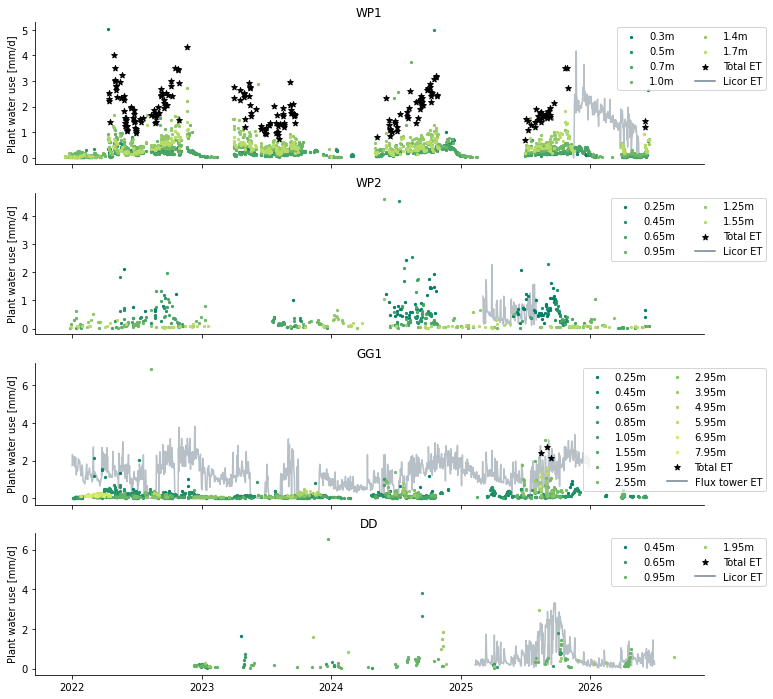

In [59]:
# plot inferred water use from subdaily data processed above against observed ET
# from licor and flux tower data. Order of magnitude and patterns are
# astonishingly reasonable

fig,axs = plt.subplots(4,figsize = (12,12),sharex=True)
for k,site in enumerate(wateruse.site.unique()[:]):
    ax = axs[k]
    cmap = plt.colormaps["summer"]

    wsub = wateruse[(wateruse.inferred_water_use>0.01)&
            (wateruse.site==site)]
    wsub['datetime'] = pd.to_datetime(wsub.date)
    wsub.set_index('datetime',inplace=True)
    wsub = wsub.sort_index()
    wsub = wsub
    colors = cmap(np.linspace(0, 1, len(wsub.depth.unique())))
    d0 = 0
    wl = []
    for j,dep in enumerate(wsub.depth.sort_values().unique()[:-2]):
        wwsub = wsub[wsub.depth==dep][['inferred_water_use']]
        wwsub['inferred_water_use'] = (float(dep)-d0)*1000*wwsub.inferred_water_use/100
        ax.scatter(wwsub.index,wwsub.inferred_water_use,
                    label=str(dep)+'m',
                   marker = 'o',s=5,
                 alpha=1.,
                   c=colors[j])
        wwsub['depth'] = dep
        wl.append(wwsub)
        d0 = float(dep)
    wl = pd.concat(wl)
    
    ax.set_title(site)
    
    ws = wl.copy()
    ws['date'] = ws.index.date
    dc = ws.groupby('date').count()
    
    tlim = 4
    if site=='GG1':
        tlim = 6
    dc = (dc[dc.depth>tlim])
    
    wl['date'] = wl.index.date
    wsub = wl[wl.date.isin(dc.index)]
    wsub = wsub.groupby(wsub.date).inferred_water_use.sum()
    ax.scatter(wsub.index,wsub,c='k',marker='*',label='Total ET')
    ax.spines[['top','right']].set_visible(False)
    ax.set_ylabel('Plant water use [mm/d]')
    if site=='GG1':
        weather = pd.read_csv('../Data/GG1/GG1_Atmospheric_TwoYrs.csv')
        weather = weather.rename(columns={' mm Precipitation':'rain_mm'})
        weather['Timestamps'] = pd.to_datetime(weather['Timestamps'])
        weather.set_index('Timestamps',inplace=True)
        weather['ET'] = np.where(weather.ET==0,
                                weather.ET.rolling(48*90).quantile(.5),
                                 weather.ET)
        weather['ET'] = weather.ET.interpolate()
        weatherD = weather.resample('D')[['ET','rain_mm']].sum()
        weatherD = weatherD.loc['4-1-2013':]
        weatherD['ET'] = weatherD['ET'].interpolate()
        ax.plot(weatherD.resample('D').mean().loc['2022-1-1':].ET,
                label='Flux tower ET',zorder=-1,alpha=.5,
               c='slategrey')
    else:
        if site=='WP1':
            licor = pd.read_csv('../Data/WP1_new/actual_evapotranspiration/licor/WP1_actual_evapotranspiration_interval.csv')
        elif site=='WP2':
            licor = pd.read_csv('../Data/WP2_new/biota/02a_actual_evapotranspiration/licor/WP2_licor_actual_et_30min.csv')
            licor['actual_et_mm'] = licor.ET_mm_interval
        elif site=='DD':
            licor = pd.read_csv('../Data/DD_new/biota/actual_evapotranspiration/licor/DD_actual_evapotranspiration_interval.csv')
        licor['DateTime'] = pd.to_datetime(licor.DateTime)
        licor.set_index('DateTime',inplace=True)
        if site=='WP2':
            licor = licor.loc['2025-03-05':'2025-08-2']
        licor = licor.resample('H')[['actual_et_mm']].sum()
        licor = licor[licor.actual_et_mm<100]
        licor['actual_et_mm0'] = np.where(licor.actual_et_mm<0,np.nan,licor.actual_et_mm)
        ax.plot(licor.resample('D').sum()['actual_et_mm0'],label='Licor ET',
               zorder = -1, c = 'slategrey',alpha=.5)
    leg = ax.legend(loc='upper right',bbox_to_anchor=(1.1,1),
                   ncols=2)
    for lh in leg.legend_handles:
        lh.set_alpha(1.0)
plt.show()

# Look at potential hydraulic redistribution
I haven't done this yet, but the rest is pretty cool, so you can get excited for this update when it's ready. Don't get too excited, though. I expect much of the potential hydraulic redistribution to be fake signal, but there might be some real signal somewhere, just haven't looked yet.